## 0. Setup

Place the eight CSVs in the working directory (Colab `/content` or local). All timestamps are
Asia/Kolkata. Currency is INR. `figures/` is created for report assets.

In [1]:
%matplotlib inline
import warnings, re, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 80)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
                     'axes.labelsize': 10, 'figure.autolayout': True})
DATA_DIR = Path('.')
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
PALETTE = {'Gen1': '#d1495b', 'Gen2': '#edae49', 'Gen3': '#2e86ab',
           '2W': '#2e86ab', '3W': '#d1495b'}

def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches='tight')
    return fig

print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 2.1.4 | numpy 1.26.4


## 1. Load the data

Explicit dtypes keep the 3.8 M-row fact table manageable. `read_table` accepts plain `.csv` or
`.csv.gz`.

In [2]:
def read_table(name, **kwargs):
    for suffix in ('.csv', '.csv.gz'):
        p = DATA_DIR / (name + suffix)
        if p.exists():
            return pd.read_csv(p, **kwargs)
    raise FileNotFoundError(name + '.csv not found in ' + str(DATA_DIR.resolve()))

swaps = read_table('swap_events', parse_dates=['event_ts'],
    dtype={'event_id':'string','rider_id':'string','station_id':'string','battery_out_id':'string',
           'battery_in_id':'string','vehicle_id':'string','city':'category','event_type':'category',
           'vehicle_class':'category','tariff_code':'category','payment_mode':'category',
           'sync_mode':'category','connectivity_tier':'category'})
stations = read_table('stations', parse_dates=['commissioned_date'], dtype={'station_id':'string'})
riders = read_table('riders', parse_dates=['signup_date'], dtype={'rider_id':'string','partner_id':'string'})
batteries = read_table('batteries', parse_dates=['commission_date','retired_date'], dtype={'battery_id':'string'})
partners = read_table('fleet_partners', parse_dates=['contract_start_date','amendment_date'], dtype={'partner_id':'string'})
tickets = read_table('support_tickets', parse_dates=['created_ts'], dtype={'ticket_id':'string','rider_id':'string'})
city_ctx = read_table('city_daily_context', parse_dates=['date'])
hourly = read_table('station_hourly_status', parse_dates=['hour_start'], dtype={'station_id':'string'})

tables = {'swap_events': swaps, 'station_hourly_status': hourly, 'stations': stations,
          'riders': riders, 'batteries': batteries, 'fleet_partners': partners,
          'support_tickets': tickets, 'city_daily_context': city_ctx}
overview = pd.DataFrame({
    'rows': {k: len(v) for k, v in tables.items()},
    'columns': {k: v.shape[1] for k, v in tables.items()},
    'grain': {'swap_events':'one swap attempt','station_hourly_status':'station x hour',
              'stations':'station','riders':'rider','batteries':'battery pack',
              'fleet_partners':'partner contract','support_tickets':'ticket',
              'city_daily_context':'city x day'}})
display(overview)
print('Attempts:', f'{len(swaps):,}', '| date span:', swaps.event_ts.min().date(), 'to', swaps.event_ts.max().date())

,rows,columns,grain
swap_events,3877013,22,one swap attempt
station_hourly_status,1487712,14,station x hour
stations,152,22,station
riders,20000,12,rider
batteries,6500,13,battery pack
fleet_partners,12,12,partner contract
support_tickets,44000,12,ticket
city_daily_context,3282,12,city x day


Attempts: 3,877,013 | date span: 2024-01-01 to 2025-06-30


## 2. Data quality audit

The brief flags several known traps. We quantify each before cleaning, because the size of the
problem determines how it should be treated.

In [3]:
print('event_id unique:', swaps.event_id.is_unique, '| duplicate ids:', int(swaps.event_id.duplicated().sum()))
print()
print('Outcomes:')
print(swaps.event_type.value_counts().to_frame('events').assign(share=lambda d: d.events/len(swaps)).to_string())
print()
print('Missing values (non-zero):')
miss = swaps.isna().sum(); miss = miss[miss > 0].sort_values(ascending=False)
print(pd.DataFrame({'missing': miss, 'pct': (miss/len(swaps)*100).round(2)}).to_string())
print()
print('Constant fields:')
for c in ['payment_mode','attempt_seq']:
    print(' ', c, '->', swaps[c].value_counts(dropna=False).to_dict())
print(' tariff_code ->', swaps.tariff_code.value_counts().to_dict())

bug = swaps.station_firmware.eq('v3.2.0') & swaps.event_ts.between('2025-03-10','2025-04-14 23:59:59')
print()
print('Timestamp-bug rows (v3.2.0, 10-Mar to 14-Apr-2025):', f'{int(bug.sum()):,}', '(', round(bug.mean()*100,2), '% )')
print('Rows flagged offline_batch:', f'{int(swaps.sync_mode.eq("offline_batch").sum()):,}',
      '(', round(swaps.sync_mode.eq('offline_batch').mean()*100,1), '% )')
print('Test-station rows (STN-TST-*):', f'{int(swaps.station_id.str.startswith("STN-TST").sum()):,}')
print()
print('Range outliers: km null', f'{int(swaps.km_since_last_swap.isna().sum()):,}',
      '| km <= 0', f'{int((swaps.km_since_last_swap<=0).sum()):,}',
      '| km > 300', f'{int((swaps.km_since_last_swap>300).sum()):,}')
print('SOC readings > 100%: in', int((swaps.soc_in_pct>100).sum()), '| out', int((swaps.soc_out_pct>100).sum()))
print()
print('Tickets: raw range', tickets.created_ts.min().date(), 'to', tickets.created_ts.max().date(),
      '| in window', f'{int(tickets.created_ts.between("2024-01-01","2025-06-30 23:59:59").sum()):,}',
      '| CSAT present', round(tickets.csat_score.notna().mean()*100,1), '%')
print('Battery retirements by month:')
print(batteries.retired_date.dt.to_period('M').value_counts().sort_index().to_string())
print('Decommissioned stations:', int(stations.decommissioned_date.notna().sum()), 'of', len(stations))
print('Telemetry status:'); print(hourly.telemetry_status.value_counts(normalize=True).round(3).to_string())
print()
print('Rider city spellings (raw):'); print(riders.home_city.value_counts().to_string())

event_id unique: True | duplicate ids: 0

Outcomes:
                            events  share
event_type                               
swap_completed             3645809  0.940
failed_no_charged_battery   134389  0.035
abandoned_queue              68533  0.018
cancelled_by_rider           16712  0.004
failed_system_error          11570  0.003

Missing values (non-zero):


                        missing   pct
battery_out_id           231204 5.960
soc_out_pct              231204 5.960
soh_out_pct              231204 5.960
energy_to_recharge_kwh   231204 5.960
battery_in_id             28282 0.730
soc_in_pct                28282 0.730
soh_in_pct                28282 0.730
km_since_last_swap        28282 0.730

Constant fields:
  payment_mode -> {'partner_invoice': 3877013}
  attempt_seq -> {1: 3877013}
 tariff_code -> {'PARTNER': 2565478, 'STD': 1095936, 'PEAK': 177879, 'OFFPEAK': 37720}



Timestamp-bug rows (v3.2.0, 10-Mar to 14-Apr-2025): 139,490 ( 3.6 % )
Rows flagged offline_batch: 591,114 ( 15.2 % )


Test-station rows (STN-TST-*): 62,031

Range outliers: km null 28,282 | km <= 0 7,814 | km > 300 7,712
SOC readings > 100%: in 0 | out 3698

Tickets: raw range 2023-03-09 to 2025-07-01 | in window 43,914 | CSAT present 34.4 %
Battery retirements by month:
retired_date
2025-06    1438
Freq: M
Decommissioned stations: 1 of 152
Telemetry status:
telemetry_status
ok        0.969
partial   0.025
missing   0.006

Rider city spellings (raw):
home_city
Bengaluru     4175
Delhi NCR     3783
Hyderabad     3396
Pune          2843
Mumbai        2772
Jaipur        2446
BLR             53
Bombay          53
bengaluru       50
MUM             49
pune            43
PUN             43
New Delhi       42
JAI             41
Gurgaon         36
Bangalore       32
HYD             31
Hyd             31
jaipur          29
hyderabad       27
Delhi           25


## 3. Cleaning and feature engineering

Cleaning order matters: fix timestamps **before** deriving hour/date/season, then de-duplicate, then
exclude test stations, then normalise cities and join attributes.

In [4]:
# 1) timestamp correction
bug = swaps.station_firmware.eq('v3.2.0') & swaps.event_ts.between('2025-03-10','2025-04-14 23:59:59')
swaps.loc[bug, 'event_ts'] = swaps.loc[bug, 'event_ts'] + pd.Timedelta(minutes=330)
print('corrected timestamps:', f'{int(bug.sum()):,}')

# 2) near-duplicate offline retries
swaps = swaps.sort_values(['rider_id','event_ts']).reset_index(drop=True)
prev = swaps.groupby(['rider_id','station_id','event_type'], observed=True, sort=False).event_ts.shift()
delta = (swaps.event_ts - prev).dt.total_seconds()
dup = swaps.sync_mode.eq('offline_batch') & delta.le(120) & delta.ge(0)
print('near-duplicates dropped:', f'{int(dup.sum()):,}')
swaps = swaps[~dup].copy()

# 3) test stations
test_rows = swaps.station_id.str.startswith('STN-TST').sum()
swaps = swaps[~swaps.station_id.str.startswith('STN-TST')].copy()
print('test-station rows removed:', f'{int(test_rows):,}')

# 4) outlier fields
swaps['km_clean'] = swaps.km_since_last_swap.where(swaps.km_since_last_swap.between(0.1, 300))
swaps.loc[swaps.soc_out_pct > 100, 'soc_out_pct'] = np.nan
swaps.loc[swaps.soc_in_pct > 100, 'soc_in_pct'] = np.nan

# 5) cities
CITY_MAP = {'blr':'Bengaluru','bengaluru':'Bengaluru','bangalore':'Bengaluru',
            'mum':'Mumbai','mumbai':'Mumbai','bombay':'Mumbai',
            'del':'Delhi NCR','delhi':'Delhi NCR','new delhi':'Delhi NCR','gurgaon':'Delhi NCR',
            'noida':'Delhi NCR','gurugram':'Delhi NCR','hyd':'Hyderabad','hyderabad':'Hyderabad',
            'pun':'Pune','pune':'Pune','jai':'Jaipur','jaipur':'Jaipur'}
def canon_city(x):
    if pd.isna(x): return 'Unknown'
    s = str(x).strip().lower()
    if s in CITY_MAP: return CITY_MAP[s]
    for k, v in CITY_MAP.items():
        if k in s: return v
    return str(x).strip().title()
riders['home_city_clean'] = riders.home_city.map(canon_city)

# 6) time features and flags
swaps['date'] = swaps.event_ts.dt.normalize()
swaps['month'] = swaps.event_ts.dt.to_period('M').astype(str)
swaps['hour'] = swaps.event_ts.dt.hour
swaps['dow'] = swaps.event_ts.dt.day_name().str[:3]
swaps['is_failed'] = (swaps.event_type != 'swap_completed').astype('int8')
swaps['season'] = pd.cut(swaps.event_ts.dt.month, [0,2,6,9,11,12],
                         labels=['Winter','Summer','Monsoon','Post-monsoon','Winter'], ordered=False)

# 7) joins
station_cols = ['station_id','city','charger_generation','location_type','expansion_wave',
                'commissioned_date','slots_2w','slots_3w','connectivity_tier','firmware_version',
                'monthly_rent_inr','monthly_maintenance_inr','grid_tariff_inr_kwh']
swaps = swaps.merge(stations[station_cols], on='station_id', how='left', suffixes=('','_stn'))
swaps = swaps.merge(riders[['rider_id','home_city_clean','signup_channel','age_band','declared_shift',
                            'plan_type','partner_id','vehicle_class']]
                    .rename(columns={'partner_id':'rider_partner_id'}), on='rider_id', how='left')
swaps = swaps.merge(partners[['partner_id','partner_name','contract_type','discount_pct']],
                    left_on='rider_partner_id', right_on='partner_id', how='left')

tickets = tickets[tickets.created_ts.between('2024-01-01','2025-06-30 23:59:59')].copy()
tickets['month'] = tickets.created_ts.dt.to_period('M').astype(str)

print()
print('Clean attempts:', f'{len(swaps):,}', '| completed:', f'{int((swaps.event_type=="swap_completed").sum()):,}',
      '| failure rate:', round(swaps.is_failed.mean(),4))
print('Cities:'); print(swaps.city.value_counts().to_string())

corrected timestamps: 139,490


near-duplicates dropped: 580


test-station rows removed: 62,031



Clean attempts: 3,814,402 | completed: 3,586,096 | failure rate: 0.0599
Cities:
city
Delhi NCR    768759
Bengaluru    763228
Hyderabad    711830
Pune         552849
Mumbai       530213
Jaipur       487523


## 4. Unit economics

In [5]:
uses = pd.concat([swaps.battery_out_id, swaps.battery_in_id]).value_counts()
batteries['uses'] = batteries.battery_id.map(uses).fillna(0).astype(int)
DESIGN_LIFE = {'2W_2.1kWh': 1250, '3W_4.8kWh': 815}
batteries['design_life'] = batteries.pack_type.map(DESIGN_LIFE)
batteries['life_used'] = np.where(batteries.retired_date.notna(),
                                  batteries.uses.clip(lower=50), batteries.design_life)
batteries['cost_per_use'] = batteries.purchase_cost_inr / batteries.life_used

completed = swaps[swaps.event_type == 'swap_completed'].copy()
completed['wear_cost'] = completed.battery_out_id.map(batteries.set_index('battery_id').cost_per_use)
completed['energy_cost'] = completed.energy_to_recharge_kwh * completed.grid_tariff_inr_kwh

st_month = completed.groupby(['station_id','month'], observed=True).size().rename('n_swaps').reset_index()
st_month = st_month.merge(stations[['station_id','monthly_rent_inr','monthly_maintenance_inr']],
                          on='station_id', how='left')
st_month['overhead_per_swap'] = ((st_month.monthly_rent_inr + st_month.monthly_maintenance_inr)
                                 / st_month.n_swaps)
completed = completed.merge(st_month[['station_id','month','overhead_per_swap']],
                            on=['station_id','month'], how='left')
completed['cm'] = completed.amount_charged_inr - completed.energy_cost - completed.wear_cost - completed.overhead_per_swap

tot = dict(attempts=len(swaps), completed=len(completed), revenue=completed.amount_charged_inr.sum(),
           energy=completed.energy_cost.sum(), wear=completed.wear_cost.sum(),
           overhead=completed.overhead_per_swap.sum(), cm=completed.cm.sum())
print(f"Attempts              {tot['attempts']:>14,}")
print(f"Completed swaps       {tot['completed']:>14,}   ({tot['completed']/tot['attempts']:.2%})")
print(f"Failed attempts       {tot['attempts']-tot['completed']:>14,}   ({(1-tot['completed']/tot['attempts']):.2%})")
for k, lab in [('revenue','Revenue'), ('energy','Energy cost'), ('wear','Battery wear'),
               ('overhead','Station overhead'), ('cm','Contribution margin')]:
    print(f"{lab:<22}{tot[k]/1e7:>8.2f} cr   ({tot[k]/tot['completed']:>7.2f} / swap)")
print()
print(f"Battery asset base: Rs {batteries.purchase_cost_inr.sum()/1e7:.2f} cr for {len(batteries):,} packs")

Attempts                   3,814,402
Completed swaps            3,586,096   (94.01%)
Failed attempts              228,306   (5.99%)
Revenue                  22.92 cr   (  63.90 / swap)
Energy cost               6.99 cr   (  19.49 / swap)
Battery wear             11.79 cr   (  32.88 / swap)
Station overhead          4.81 cr   (  13.41 / swap)
Contribution margin      -0.68 cr   (  -1.88 / swap)

Battery asset base: Rs 24.32 cr for 6,500 packs


In [6]:
base = tot['cm'] / tot['completed']
rows = [
    ('Base case', base),
    ('Energy at metered grid kWh (x1.53)', base - 0.53*tot['energy']/tot['completed']),
    ('Wear life 20% shorter', base - 0.20*tot['wear']/tot['completed']),
    ('Wear life 20% longer', base + (tot['wear'] - tot['wear']/1.2)/tot['completed']),
    ('Exclude station rent + maintenance', base + tot['overhead']/tot['completed']),
    ('Revenue net of 15% discount leak', base - 0.15*completed.amount_charged_inr.mean()),
]
sens = pd.DataFrame(rows, columns=['scenario','cm_per_swap']).set_index('scenario')
display(sens.round(2))
print('Range: Rs %.2f to Rs %.2f per swap' % (sens.cm_per_swap.min(), sens.cm_per_swap.max()))

,cm_per_swap
scenario,
Base case,-1.880
Energy at metered grid kWh (x1.53),-12.220
Wear life 20% shorter,-8.460
Wear life 20% longer,3.600
Exclude station rent + maintenance,11.530
Revenue net of 15% discount leak,-11.470


Range: Rs -12.22 to Rs 11.53 per swap


## 5. Question 1 — Network performance over time

We track completed swaps, revenue, failure rate, and contribution margin per swap monthly, then
separate **volume** from **unit economics**.

In [7]:
agg = (swaps.groupby('month', observed=True)
        .agg(attempts=('event_id','size'), failed=('is_failed','sum'), days=('date','nunique')))
agg['completed'] = agg.attempts - agg.failed
agg['fail_rate'] = agg.failed / agg.attempts
agg['swaps_per_day'] = agg.completed / agg.days
rev = (completed.groupby('month', observed=True)
        .agg(revenue=('amount_charged_inr','sum'), energy=('energy_cost','sum'),
             wear=('wear_cost','sum'), overhead=('overhead_per_swap','sum'),
             cm=('cm','sum'), riders=('rider_id','nunique')))
kpi = agg.join(rev)
kpi['rev_per_swap'] = kpi.revenue / kpi.completed
kpi['cm_per_swap'] = kpi.cm / kpi.completed
kpi['oh_per_swap'] = kpi.overhead / kpi.completed
kpi['en_per_swap'] = kpi.energy / kpi.completed
display(kpi[['attempts','completed','swaps_per_day','fail_rate','revenue',
             'rev_per_swap','cm_per_swap','oh_per_swap','riders']].round(3))

,attempts,completed,swaps_per_day,fail_rate,revenue,rev_per_swap,cm_per_swap,oh_per_swap,riders
month,,,,,,,,,
2024-01,108265,103495,"3,338.548",0.044,"6,198,034.400",59.887,-14.514,20.379,4179
2024-02,109263,104429,"3,601.000",0.044,"6,255,843.600",59.905,-14.254,20.196,4441
2024-03,121479,116140,"3,746.452",0.044,"6,952,182.400",59.860,-11.975,18.160,4738
2024-04,128980,120106,"4,003.533",0.069,"7,203,413.400",59.975,-11.261,17.560,5075
2024-05,143173,125438,"4,046.387",0.124,"7,512,333.800",59.889,-10.193,16.814,5477
2024-06,145872,130872,"4,362.400",0.103,"7,826,891.200",59.806,-9.121,16.116,5827
2024-07,155329,148597,"4,793.452",0.043,"9,665,836.400",65.047,-1.879,14.193,6174
2024-08,168884,161672,"5,215.226",0.043,"10,508,484.100",64.999,-2.160,14.668,6708
2024-09,192451,184023,"6,134.100",0.044,"11,901,560.150",64.674,-2.420,13.850,7227


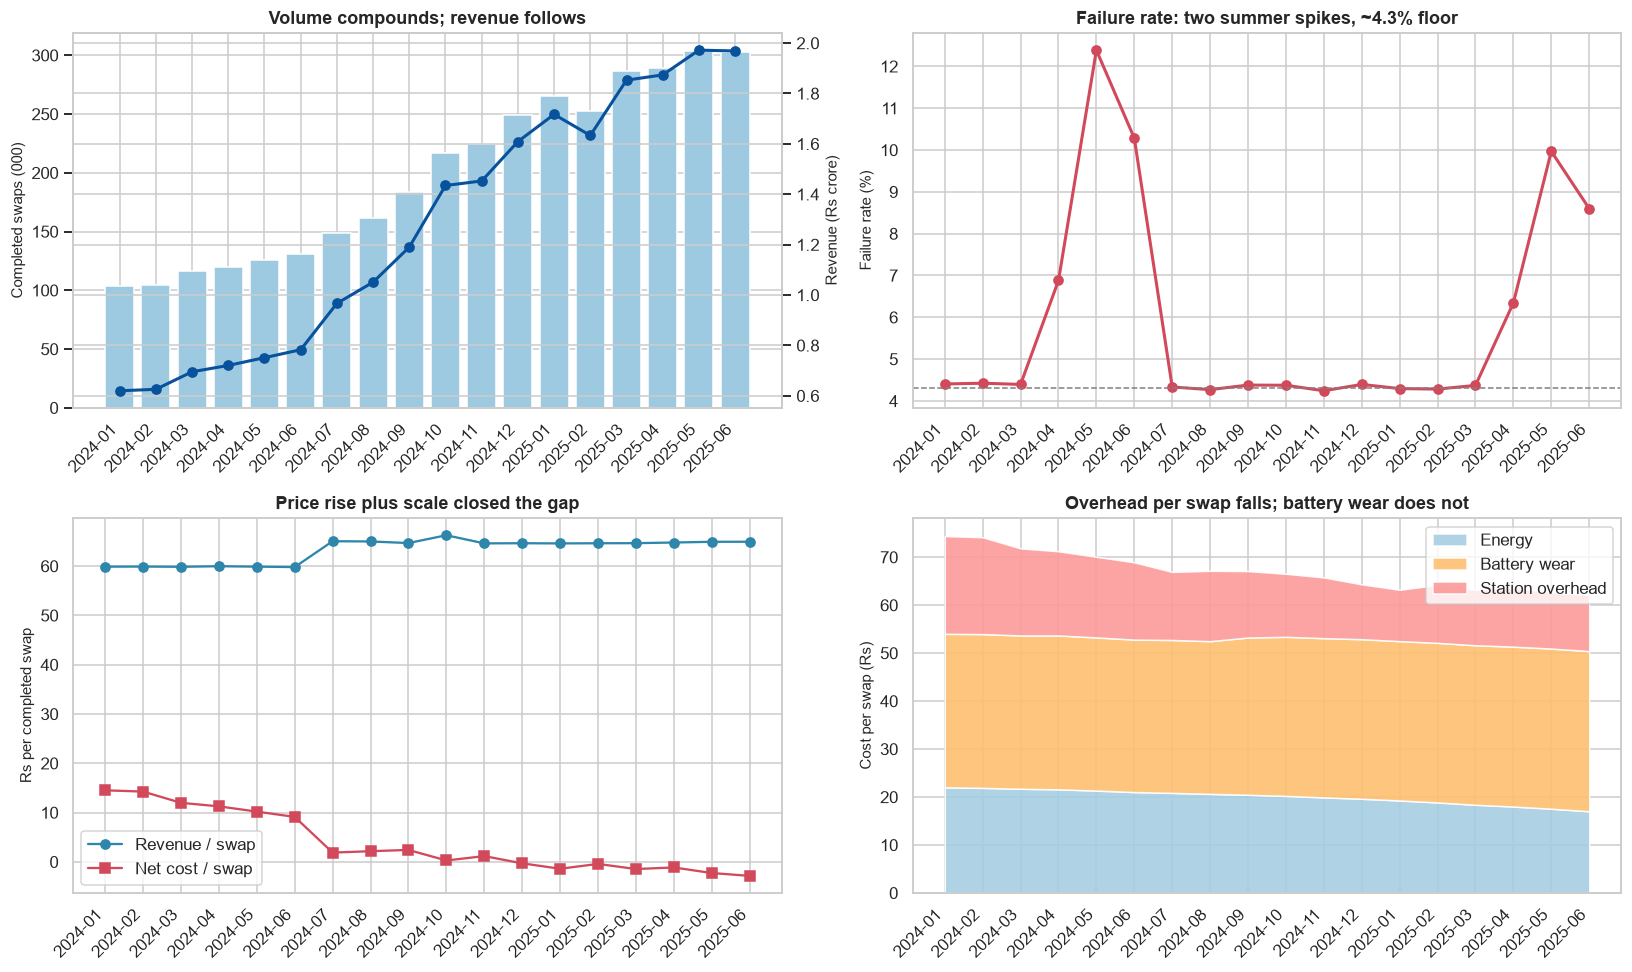

In [8]:
x = np.arange(len(kpi)); labels = kpi.index
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
a = ax[0,0]
a.bar(x, kpi.completed/1e3, color='#9ecae1')
a.set_ylabel('Completed swaps (000)'); a.set_xticks(x); a.set_xticklabels(labels, rotation=45, ha='right')
a2 = a.twinx(); a2.plot(x, kpi.revenue/1e7, color='#08519c', marker='o', lw=2)
a2.set_ylabel('Revenue (Rs crore)'); a.set_title('Volume compounds; revenue follows')

a = ax[0,1]
a.plot(x, kpi.fail_rate*100, color='#d1495b', marker='o', lw=2)
a.set_ylabel('Failure rate (%)'); a.set_xticks(x); a.set_xticklabels(labels, rotation=45, ha='right')
a.set_title('Failure rate: two summer spikes, ~4.3% floor'); a.axhline(4.3, ls='--', color='grey', lw=1)

a = ax[1,0]
a.plot(x, kpi.rev_per_swap, marker='o', label='Revenue / swap', color='#2e86ab')
a.plot(x, -kpi.cm_per_swap, marker='s', label='Net cost / swap', color='#d1495b')
a.set_ylabel('Rs per completed swap'); a.set_xticks(x); a.set_xticklabels(labels, rotation=45, ha='right')
a.set_title('Price rise plus scale closed the gap'); a.legend()

a = ax[1,1]
a.stackplot(x, kpi.en_per_swap, kpi.wear/kpi.completed, kpi.oh_per_swap,
            labels=['Energy','Battery wear','Station overhead'],
            colors=['#a6cee3','#fdbf6f','#fb9a99'], alpha=.9)
a.set_ylabel('Cost per swap (Rs)'); a.set_xticks(x); a.set_xticklabels(labels, rotation=45, ha='right')
a.set_title('Overhead per swap falls; battery wear does not'); a.legend(loc='upper right')
save(fig, 'f01_monthly_kpis.png')
plt.show()

In [9]:
growth = pd.DataFrame({
    'Completed swaps': kpi.completed / kpi.completed.iloc[0] * 100,
    'Revenue': kpi.revenue / kpi.revenue.iloc[0] * 100,
    'Revenue / swap': kpi.rev_per_swap / kpi.rev_per_swap.iloc[0] * 100}, index=kpi.index)
print('Indexed to Jan-2024 = 100:')
print(growth.round(1).iloc[[0,5,6,11,17]].to_string())
q = (completed.assign(quarter=completed.event_ts.dt.to_period('Q').astype(str))
     .groupby('quarter', observed=True)
     .agg(completed=('event_id','size'), revenue=('amount_charged_inr','sum'),
          rev_ps=('amount_charged_inr','mean'), cm_ps=('cm','mean')))
q['revenue_cr'] = q.revenue/1e7
print()
print(q[['completed','revenue_cr','rev_ps','cm_ps']].round(2).to_string())
print()
print('Total growth: revenue %.2fx, volume %.2fx, realised price %.2fx' % (
    growth.Revenue.iloc[-1]/100, growth['Completed swaps'].iloc[-1]/100,
    growth['Revenue / swap'].iloc[-1]/100))

Indexed to Jan-2024 = 100:
         Completed swaps  Revenue  Revenue / swap
month                                            
2024-01          100.000  100.000         100.000
2024-06          126.500  126.300          99.900
2024-07          143.600  156.000         108.600
2024-12          240.500  259.600         107.900
2025-06          292.900  317.600         108.400



         completed  revenue_cr  rev_ps   cm_ps
quarter                                       
2024Q1      324064       1.940  59.880 -13.520
2024Q2      376416       2.250  59.890 -10.160
2024Q3      494292       3.210  64.890  -2.170
2024Q4      690251       4.500  65.140  -0.360
2025Q1      805053       5.200  64.630   1.110
2025Q2      896020       5.810  64.890   2.100

Total growth: revenue 3.18x, volume 2.93x, realised price 1.08x


**Reading Q1.** Volume grew every month except February and reached 10.1 k completed swaps/day.
Realised price stepped up ₹59.9 → ₹65.0 in July 2024 (list ₹64.7 → ₹70.2) and then held flat;
discounts absorbed part of the increase. Margin recovery came from **price (+₹5.1)** and **station
overhead leverage (₹20.4 → ₹11.7 per swap)** plus **cheaper energy per swap (₹22.0 → ₹17.0)**.
Battery wear stayed near ₹33 and is now **51% of revenue** — the largest and least managed cost line.

**Q1 answer:** the network is growing and has crossed into positive contribution per swap, but the
improvement is price plus utilisation, not cost engineering. Recent growth is still ~95% volume.

## 6. Question 2 — Service failures and customer experience

A failed attempt is one of four outcomes: no charged battery, abandoned queue, rider cancellation, or
system error. We locate failures by time, weather, asset and vehicle, then translate them into lost
revenue.

,events,share,lost_revenue_cr
event_type,,,
swap_completed,3586096,0.940,22.916
failed_no_charged_battery,132785,0.035,0.849
abandoned_queue,67663,0.018,0.432
cancelled_by_rider,16458,0.004,0.105
failed_system_error,11400,0.003,0.073


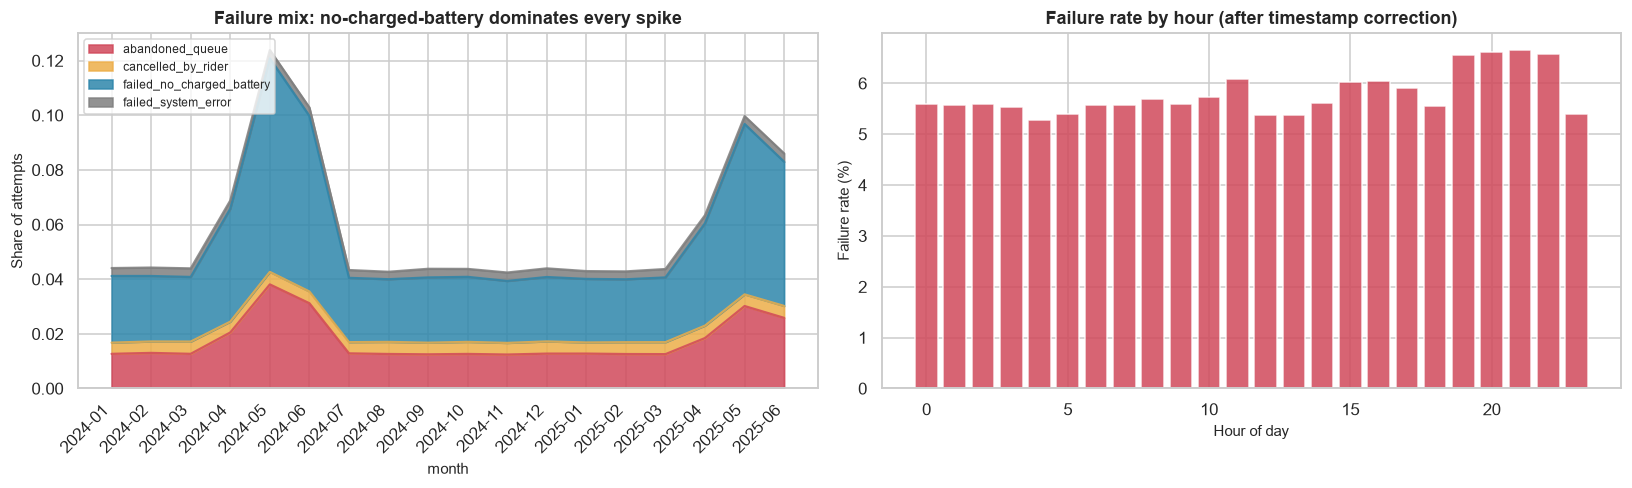

Evening 19-22: 6.60% vs off-peak 5.61%


In [10]:
mix = swaps.event_type.value_counts().rename('events').to_frame()
mix['share'] = mix.events / len(swaps)
mix['lost_revenue_cr'] = mix.events * completed.amount_charged_inr.mean() / 1e7
display(mix.round(4))

fm = pd.crosstab(swaps.month, swaps.event_type, normalize='index').drop(columns='swap_completed')
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
fm.plot.area(ax=ax[0], color=['#d1495b','#edae49','#2e86ab','#7f7f7f'], alpha=.85)
ax[0].set_title('Failure mix: no-charged-battery dominates every spike')
ax[0].set_ylabel('Share of attempts'); ax[0].set_xticks(range(len(fm)))
ax[0].set_xticklabels(fm.index, rotation=45, ha='right'); ax[0].legend(loc='upper left', fontsize=8)
hr = swaps.groupby('hour', observed=True).agg(fail=('is_failed','mean'))
ax[1].bar(hr.index, hr.fail*100, color='#d1495b', alpha=.85)
ax[1].set_title('Failure rate by hour (after timestamp correction)')
ax[1].set_xlabel('Hour of day'); ax[1].set_ylabel('Failure rate (%)')
save(fig, 'f02_failure_mix_hour.png')
plt.show()
print('Evening 19-22: %.2f%% vs off-peak %.2f%%' % (
    swaps[swaps.hour.isin([19,20,21,22])].is_failed.mean()*100,
    swaps[~swaps.hour.isin([19,20,21,22])].is_failed.mean()*100))

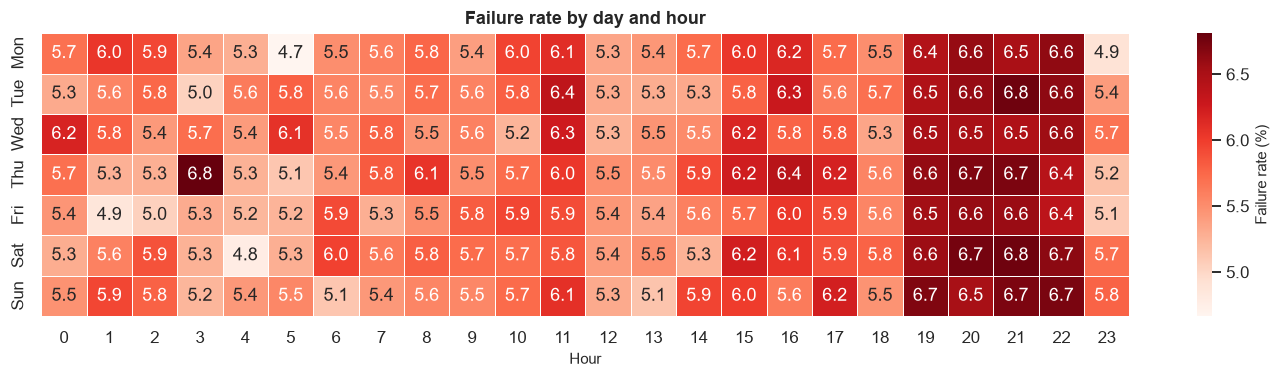

In [11]:
hm = swaps.pivot_table(index='dow', columns='hour', values='is_failed', aggfunc='mean') * 100
hm = hm.reindex(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
fig, ax = plt.subplots(figsize=(13, 3.6))
sns.heatmap(hm, cmap='Reds', annot=True, fmt='.1f', cbar_kws={'label':'Failure rate (%)'},
            linewidths=.4, ax=ax)
ax.set_title('Failure rate by day and hour'); ax.set_xlabel('Hour'); ax.set_ylabel('')
save(fig, 'f03_heatmap_hour_dow.png')
plt.show()

Correlation with daily failure rate:
max_temp_c           0.704
grid_outage_hours    0.253
rainfall_mm         -0.051
fail                 1.000

Heat-alert days: 15.99% vs 5.46% (n=150 / 3132)


,days,attempts,fail_pct
max_temp_c,,,
"(0, 20]",953,1110395,4.350
"(20, 25]",930,985791,4.350
"(25, 30]",403,435355,4.370
"(30, 35]",414,507999,4.450
"(35, 40]",347,467083,11.430
"(40, 50]",235,307779,15.860


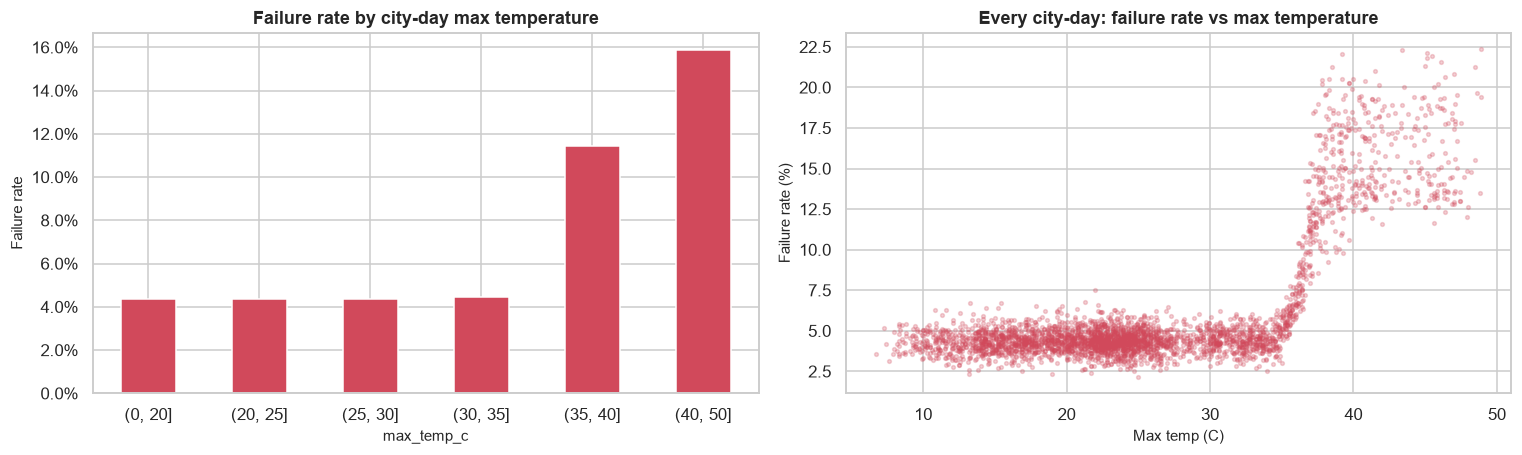

In [12]:
ctx = city_ctx.copy(); ctx['city'] = ctx.city.astype(str)
dly = (swaps.assign(city=swaps.city.astype(str)).groupby(['date','city'], observed=True)
       .agg(attempts=('is_failed','size'), fail=('is_failed','mean')).reset_index())
dly = dly.merge(ctx[['date','city','max_temp_c','heat_alert','grid_outage_hours','rainfall_mm']],
                on=['date','city'], how='left')
print('Correlation with daily failure rate:')
print(dly[['max_temp_c','grid_outage_hours','rainfall_mm','fail']].corr()['fail'].round(3).to_string())
print()
print('Heat-alert days: %.2f%% vs %.2f%% (n=%d / %d)' % (
    dly[dly.heat_alert==True].fail.mean()*100, dly[dly.heat_alert==False].fail.mean()*100,
    int(dly.heat_alert.sum()), int((dly.heat_alert==False).sum())))
tb = dly.groupby(pd.cut(dly.max_temp_c, [0,20,25,30,35,40,50]), observed=True).agg(
        days=('date','size'), attempts=('attempts','sum'), fail=('fail','mean'))
display(tb.assign(fail_pct=lambda d: d.fail*100).drop(columns='fail').round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
tb.fail.plot.bar(ax=ax[0], color='#d1495b')
ax[0].set_title('Failure rate by city-day max temperature'); ax[0].set_ylabel('Failure rate')
ax[0].set_xticklabels([str(i) for i in tb.index], rotation=0)
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax[1].scatter(dly.max_temp_c, dly.fail*100, s=6, alpha=.25, color='#d1495b')
ax[1].set_title('Every city-day: failure rate vs max temperature')
ax[1].set_xlabel('Max temp (C)'); ax[1].set_ylabel('Failure rate (%)')
save(fig, 'f04_temperature_failure.png')
plt.show()

Daily panel correlations (n=3282):
fail      1.000
charge    0.638
cab       0.677
stock    -0.456
quar      0.579


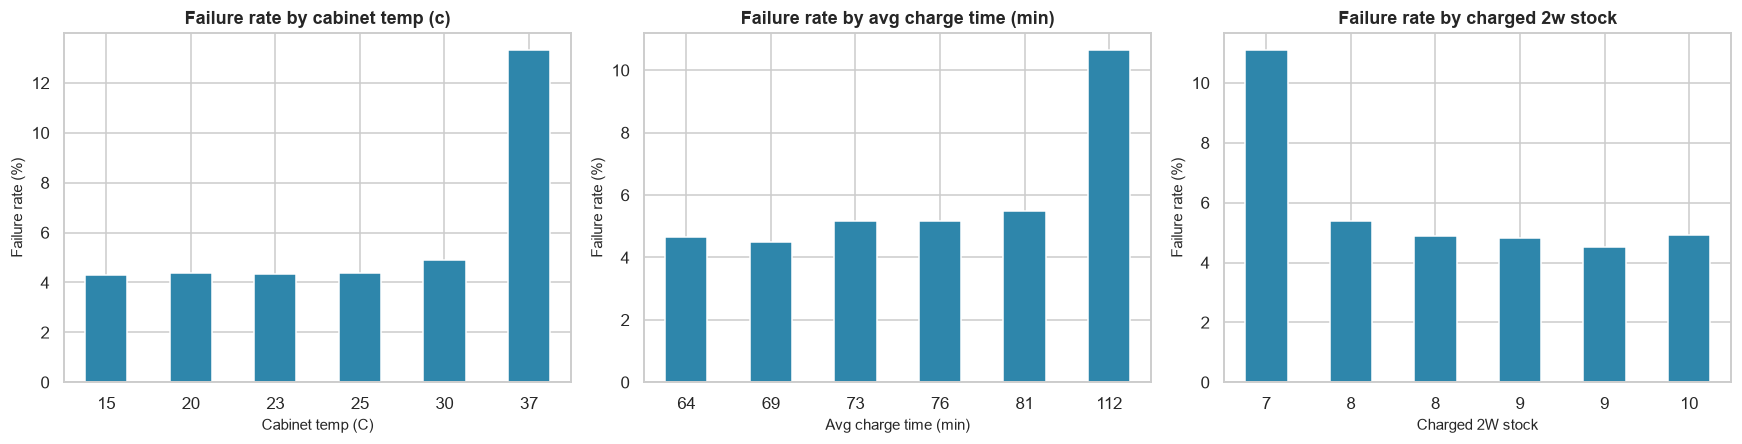


Cabinet >35C: 15.74% vs 5.17%
Charge >90 min: 16.92% vs <80 min 4.98%


In [13]:
h = hourly.copy(); h['station_id'] = h.station_id.astype(str)
h['city'] = h.station_id.str[4:7].map({'BLR':'Bengaluru','DEL':'Delhi NCR','HYD':'Hyderabad',
                                        'PUN':'Pune','MUM':'Mumbai','JAI':'Jaipur'})
h['date'] = h.hour_start.dt.normalize()
hd = h.groupby(['date','city'], observed=True).agg(charge=('avg_charge_minutes','mean'),
        cab=('cabinet_temp_c','mean'), stock=('charged_2w_avg','mean'),
        quar=('packs_quarantined','sum')).reset_index()
panel = dly.merge(hd, on=['date','city'], how='left')
print('Daily panel correlations (n=%d):' % len(panel))
print(panel[['fail','charge','cab','stock','quar']].corr()['fail'].round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, col, lab in zip(ax, ['cab','charge','stock'],
                       ['Cabinet temp (C)','Avg charge time (min)','Charged 2W stock']):
    bins = pd.qcut(panel[col], 6, duplicates='drop')
    g = panel.groupby(bins, observed=True).fail.mean()*100
    g.plot.bar(ax=a, color='#2e86ab')
    a.set_title('Failure rate by ' + lab.lower()); a.set_ylabel('Failure rate (%)')
    a.set_xlabel(lab); a.set_xticklabels([f'{i.mid:.0f}' for i in g.index], rotation=0)
save(fig, 'f05_telemetry_drivers.png')
plt.show()
print()
print('Cabinet >35C: %.2f%% vs %.2f%%' % (panel[panel.cab>35].fail.mean()*100,
                                            panel[panel.cab<=35].fail.mean()*100))
print('Charge >90 min: %.2f%% vs <80 min %.2f%%' % (panel[panel.charge>90].fail.mean()*100,
                                                     panel[panel.charge<80].fail.mean()*100))

By vehicle class:


,attempts,fail,riders,share
vehicle_class,,,,
2W,3399018,0.054,17065,0.891
3W,415384,0.104,2876,0.109


By charger generation:


,attempts,fail,share
charger_generation,,,
Gen1,1821751,0.072,0.478
Gen2,1620468,0.048,0.425
Gen3,372183,0.048,0.098


By city:


,attempts,fail,abandoned
city,,,
Bengaluru,763228,0.046,0.013
Delhi NCR,768759,0.074,0.022
Hyderabad,711830,0.067,0.020
Jaipur,487523,0.078,0.024
Mumbai,530213,0.044,0.013
Pune,552849,0.050,0.015


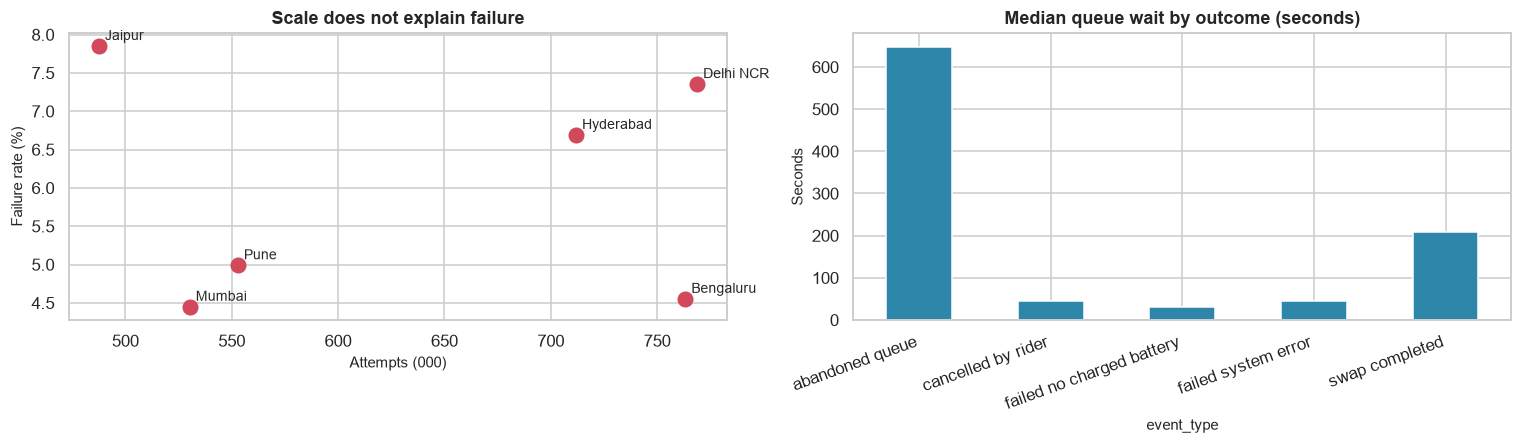


Abandoned: 67663 (median wait 648s, p90 1088s)


In [14]:
print('By vehicle class:')
display(swaps.groupby('vehicle_class', observed=True).agg(attempts=('event_id','size'),
        fail=('is_failed','mean'), riders=('rider_id','nunique'),
        share=('event_id', lambda s: len(s)/len(swaps))).round(3))
print('By charger generation:')
display(swaps.groupby('charger_generation', observed=True).agg(attempts=('event_id','size'),
        fail=('is_failed','mean'), share=('event_id', lambda s: len(s)/len(swaps))).round(3))
print('By city:')
display(swaps.groupby('city', observed=True).agg(attempts=('event_id','size'),
        fail=('is_failed','mean'), abandoned=('event_type', lambda s: (s=='abandoned_queue').mean())).round(3))

city = swaps.groupby('city', observed=True).agg(fail=('is_failed','mean'), attempts=('event_id','size'))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].scatter(city.attempts/1e3, city.fail*100, s=90, color='#d1495b')
for c, r in city.iterrows():
    ax[0].annotate(c, (r.attempts/1e3, r.fail*100), fontsize=9, xytext=(4,4), textcoords='offset points')
ax[0].set_xlabel('Attempts (000)'); ax[0].set_ylabel('Failure rate (%)')
ax[0].set_title('Scale does not explain failure')
q = swaps.groupby('event_type', observed=True).queue_wait_sec.quantile([.5,.9]).unstack()
q[.5].plot.bar(ax=ax[1], color='#2e86ab')
ax[1].set_title('Median queue wait by outcome (seconds)'); ax[1].set_ylabel('Seconds')
ax[1].set_xticklabels([t.get_text().replace('_',' ') for t in ax[1].get_xticklabels()], rotation=20, ha='right')
save(fig, 'f06_city_queue.png')
plt.show()
print()
print('Abandoned: %d (median wait %.0fs, p90 %.0fs)' % (
    int((swaps.event_type=='abandoned_queue').sum()),
    swaps[swaps.event_type=='abandoned_queue'].queue_wait_sec.median(),
    swaps[swaps.event_type=='abandoned_queue'].queue_wait_sec.quantile(.9)))

**Q2 answer.** Failures are dominated by **no charged battery** (58% of failures) and **queue
abandonment** (29%). They are not random: summer runs at **7.8%** versus ~4.3% in other seasons;
heat-alert days fail at **16.0%** versus 5.5%; cabinet temperature above 35 °C coincides with
**15.7%** failure; charge time above 90 minutes coincides with **16.9%** failure versus 5.0% below
80 minutes. Evening hours (19:00–22:00) are ~1.1 pp worse than off-peak — a real but secondary
effect once the timestamp bug is corrected. 3W fails at 10.4% versus 5.5% for 2W; Gen-1 at 7.2%
versus 4.8%.

The mechanism is consistent across all four views: heat and low stock lengthen charging beyond rider
tolerance, which surfaces as no-battery and abandonment. The 228 k failed attempts represent
**₹1.46 cr of foregone revenue**; the retention cost is additional (Section 10).

## 7. Question 3 — Station and geographic patterns

We combine station master data (generation, location, rent, commissioning wave) with swap outcomes
and hourly telemetry (charge time, cabinet temperature, outages).

In [15]:
st = (swaps.groupby('station_id', observed=True)
        .agg(attempts=('event_id','size'), fail=('is_failed','mean'),
             abandoned=('event_type', lambda s: (s=='abandoned_queue').mean())))
st = st.join(completed.groupby('station_id', observed=True)
             .agg(completed=('event_id','size'), revenue=('amount_charged_inr','sum'), cm_ps=('cm','mean')))
st = st.reset_index().merge(stations, on='station_id', how='left')
chg = h.groupby('station_id', observed=True).agg(charge_min=('avg_charge_minutes','mean'),
        cabinet=('cabinet_temp_c','mean'), outage=('outage_minutes','mean')).reset_index()
st = st.merge(chg, on='station_id', how='left')
st['slots'] = st.slots_2w + st.slots_3w
st['active_months'] = st.station_id.map(swaps.groupby('station_id').month.nunique())
st['per_slot_day'] = st.attempts / (st.slots * 30 * st.active_months.clip(lower=1))

print('Station failure distribution:')
print(st.fail.describe(percentiles=[.1,.25,.5,.75,.9,.95]).round(3).to_string())
top = st.sort_values('fail', ascending=False)
print()
print('Worst 10 stations:')
display(top[['station_id','city','charger_generation','location_type','attempts','fail','charge_min','cm_ps']].head(10).round(3))
print('Best 10 stations:')
display(top[['station_id','city','charger_generation','location_type','attempts','fail','charge_min','cm_ps']].tail(10).round(3))
n20 = int(np.ceil(len(st)*0.2))
print()
print('Top %d%% of stations carry %.1f%% of failures and %.1f%% of attempts' % (
    int(round(n20/len(st)*100)),
    top.head(n20).fail.mul(top.head(n20).attempts).sum() / swaps.is_failed.sum() * 100,
    top.head(n20).attempts.sum() / len(swaps) * 100))

Station failure distribution:
count   150.000
mean      0.057
std       0.015
min       0.041
10%       0.044
25%       0.046
50%       0.050
75%       0.060
90%       0.084
95%       0.087
max       0.091

Worst 10 stations:


,station_id,city,charger_generation,location_type,attempts,fail,charge_min,cm_ps
36,STN-DEL-037,Delhi NCR,Gen1,commercial_hub,30838,0.091,93.973,-2.566
47,STN-DEL-048,Delhi NCR,Gen1,market,34646,0.090,93.882,-2.723
92,STN-JAI-137,Jaipur,Gen1,commercial_hub,44349,0.088,94.805,0.361
97,STN-JAI-142,Jaipur,Gen1,commercial_hub,33307,0.087,94.712,-4.388
96,STN-JAI-141,Jaipur,Gen1,commercial_hub,45594,0.087,94.745,1.370
44,STN-DEL-045,Delhi NCR,Gen1,commercial_hub,32237,0.087,94.044,-7.588
91,STN-JAI-136,Jaipur,Gen1,transit_hub,29340,0.087,94.808,-10.859
93,STN-JAI-138,Jaipur,Gen1,market,48924,0.087,94.692,0.557
39,STN-DEL-040,Delhi NCR,Gen1,market,40317,0.086,93.942,-3.901
49,STN-DEL-050,Delhi NCR,Gen1,commercial_hub,47034,0.086,93.915,0.949


Best 10 stations:


,station_id,city,charger_generation,location_type,attempts,fail,charge_min,cm_ps
2,STN-BLR-003,Bengaluru,Gen2,commercial_hub,40241,0.043,64.038,8.269
25,STN-BLR-026,Bengaluru,Gen2,highway_fuel_pump,13754,0.043,64.051,-1.613
108,STN-MUM-113,Mumbai,Gen2,commercial_hub,40607,0.042,63.992,-10.755
20,STN-BLR-021,Bengaluru,Gen2,highway_fuel_pump,12097,0.042,64.176,4.416
124,STN-MUM-129,Mumbai,Gen3,market,8367,0.042,42.003,0.333
111,STN-MUM-116,Mumbai,Gen2,market,36170,0.042,64.032,-6.655
149,STN-PUN-110,Pune,Gen3,market,8081,0.042,42.139,6.633
125,STN-MUM-130,Mumbai,Gen3,highway_fuel_pump,3901,0.042,42.010,-18.936
23,STN-BLR-024,Bengaluru,Gen2,residential,23561,0.042,64.041,4.442
120,STN-MUM-125,Mumbai,Gen2,residential,14360,0.041,64.032,-4.323



Top 20% of stations carry 40.6% of failures and 29.2% of attempts


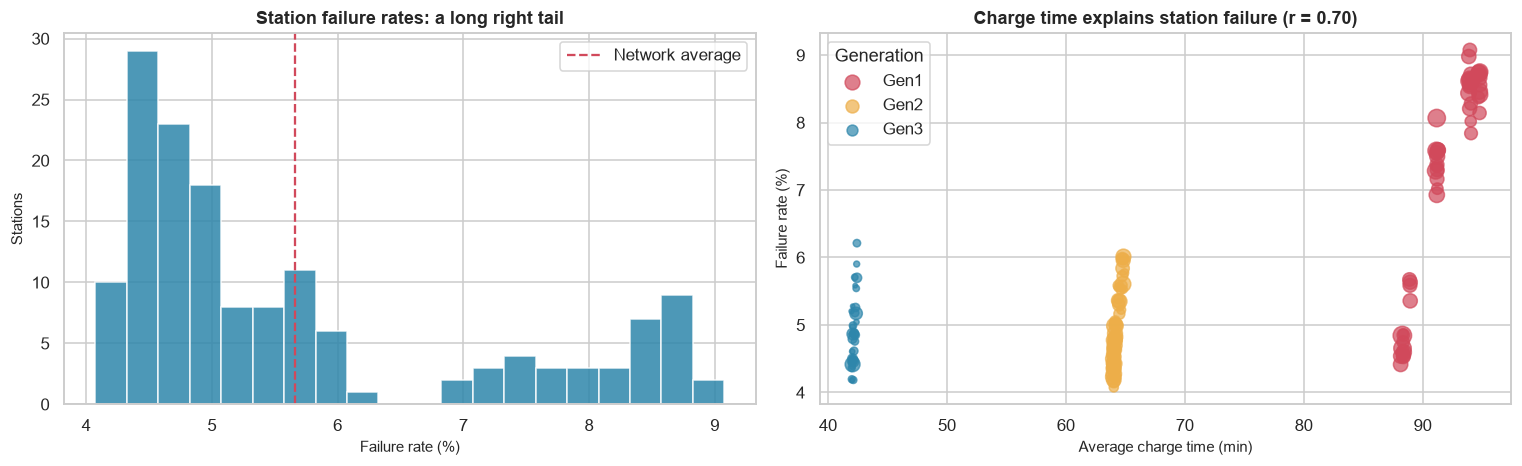

Correlations: fail vs charge 0.70 | cabinet -0.13 | outage -0.16


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].hist(st.fail*100, bins=20, color='#2e86ab', alpha=.85)
ax[0].axvline(st.fail.mean()*100, color='#d1495b', ls='--', label='Network average')
ax[0].set_title('Station failure rates: a long right tail'); ax[0].set_xlabel('Failure rate (%)')
ax[0].set_ylabel('Stations'); ax[0].legend()
for gen, g in st.dropna(subset=['charge_min']).groupby('charger_generation', observed=True):
    ax[1].scatter(g.charge_min, g.fail*100, s=g.attempts/400, alpha=.7,
                  color=PALETTE.get(gen, 'grey'), label=gen)
ax[1].set_xlabel('Average charge time (min)'); ax[1].set_ylabel('Failure rate (%)')
ax[1].set_title('Charge time explains station failure (r = %.2f)' % st.fail.corr(st.charge_min))
ax[1].legend(title='Generation')
save(fig, 'f07_station_distribution.png')
plt.show()
print('Correlations: fail vs charge %.2f | cabinet %.2f | outage %.2f' % (
    st.fail.corr(st.charge_min), st.fail.corr(st.cabinet), st.fail.corr(st.outage)))

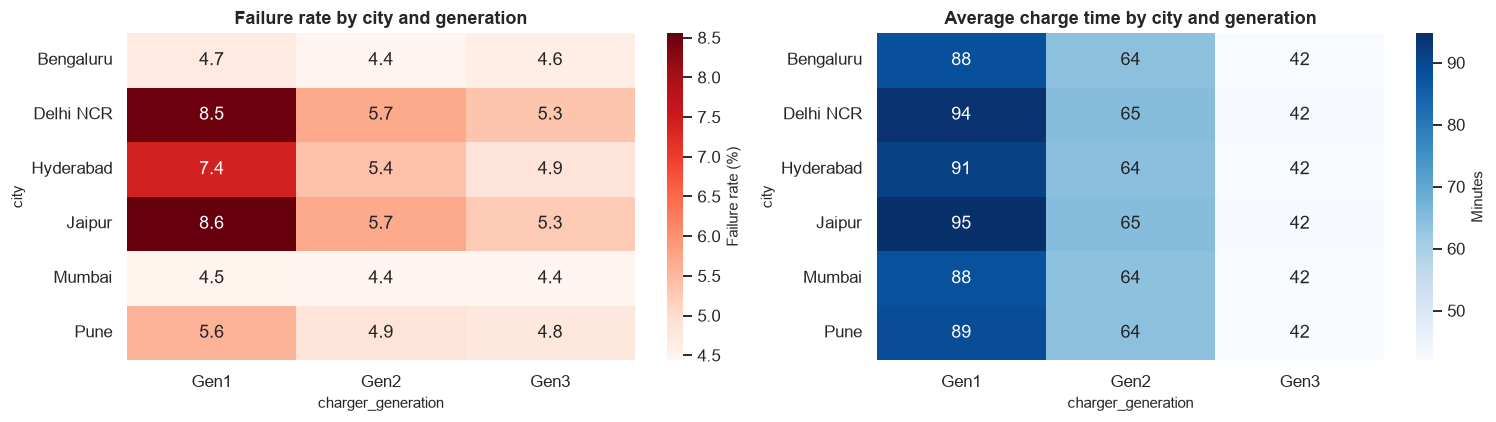

By location type:


,stations,attempts,fail
location_type,,,
commercial_hub,44,1535483,0.060
highway_fuel_pump,21,329761,0.051
market,47,1246758,0.059
residential,21,382227,0.052
tech_park,7,147513,0.053
transit_hub,10,172660,0.056


By commissioning vintage:


,stations,attempts,fail,charge
vintage,,,,
2023,90,3068385,0.061,79.844
2024,30,500998,0.049,59.161
2025,30,245019,0.050,42.168



Model A (no charge time) R2 = 0.834
C(charger_generation)[T.Gen2]   -0.017
C(charger_generation)[T.Gen3]   -0.022
Model B (+ charge time) R2 = 0.959
C(charger_generation)[T.Gen2]   0.117
C(charger_generation)[T.Gen3]   0.226
charge_min                      0.005

Each +10 min average charge is associated with +5.02 pp failure


In [17]:
import statsmodels.formula.api as smf
pv = st.pivot_table(index='city', columns='charger_generation', values='fail', aggfunc='mean')*100
pc = st.pivot_table(index='city', columns='charger_generation', values='charge_min', aggfunc='mean')
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(pv, annot=True, fmt='.1f', cmap='Reds', ax=ax[0], cbar_kws={'label':'Failure rate (%)'})
ax[0].set_title('Failure rate by city and generation')
sns.heatmap(pc, annot=True, fmt='.0f', cmap='Blues', ax=ax[1], cbar_kws={'label':'Minutes'})
ax[1].set_title('Average charge time by city and generation')
save(fig, 'f08_city_generation.png')
plt.show()

print('By location type:')
display(st.groupby('location_type', observed=True).agg(stations=('station_id','size'),
        attempts=('attempts','sum'), fail=('fail','mean')).round(3))
print('By commissioning vintage:')
st['vintage'] = pd.cut(st.commissioned_date.dt.year, [2022,2023,2024,2025], labels=['2023','2024','2025'])
display(st.groupby('vintage', observed=True).agg(stations=('station_id','size'),
        attempts=('attempts','sum'), fail=('fail','mean'), charge=('charge_min','mean')).round(3))

m1 = smf.ols('fail ~ C(charger_generation) + C(city) + np.log1p(attempts)', data=st).fit()
m2 = smf.ols('fail ~ C(charger_generation) + C(city) + np.log1p(attempts) + charge_min', data=st).fit()
print()
print('Model A (no charge time) R2 = %.3f' % m1.rsquared)
print(m1.params[['C(charger_generation)[T.Gen2]','C(charger_generation)[T.Gen3]']].round(4).to_string())
print('Model B (+ charge time) R2 = %.3f' % m2.rsquared)
print(m2.params[['C(charger_generation)[T.Gen2]','C(charger_generation)[T.Gen3]','charge_min']].round(4).to_string())
print()
print('Each +10 min average charge is associated with %+.2f pp failure' % (m2.params['charge_min']*10*100))

Tickets per 1,000 attempts: median 10.9, p90 14.0, max 16.2
Station failure rate vs tickets/1k: r = 0.63


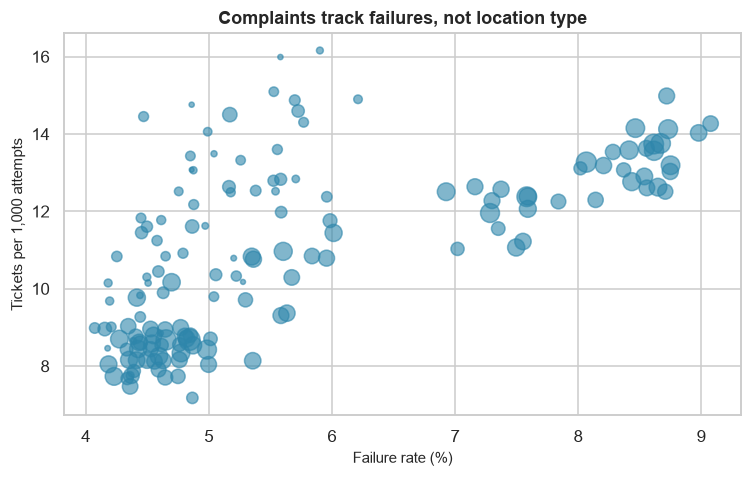

In [18]:
tk = tickets.groupby('station_id', observed=True).size().rename('tickets')
st = st.merge(tk, on='station_id', how='left')
st['tickets'] = st.tickets.fillna(0)
st['tickets_per_1k'] = st.tickets / (st.attempts/1000)
print('Tickets per 1,000 attempts: median %.1f, p90 %.1f, max %.1f' % (
    st.tickets_per_1k.median(), st.tickets_per_1k.quantile(.9), st.tickets_per_1k.max()))
print('Station failure rate vs tickets/1k: r = %.2f' % st.fail.corr(st.tickets_per_1k))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(st.fail*100, st.tickets_per_1k, s=st.attempts/300, alpha=.6, color='#2e86ab')
ax.set_xlabel('Failure rate (%)'); ax.set_ylabel('Tickets per 1,000 attempts')
ax.set_title('Complaints track failures, not location type')
save(fig, 'f09_tickets_vs_fail.png')
plt.show()

**Q3 answer.** Station performance is an **equipment and thermal** story, not a location story:

- Gen-1 cabinets average **91.8 minutes** per charge versus 64.3 (Gen-2) and 42.2 (Gen-3) and fail at
  **7.2% versus 4.8%**. They are 48% of attempts but **57% of failures**. Adding charge time to a
  station regression lifts R² from 0.83 to 0.96 and flips the generation coefficient — charge time is
  the mechanism.
- **20% of stations (30 of 150) generate 41% of failures** while carrying 29% of attempts.
- City differences are largely compositional: Delhi NCR and Jaipur carry the oldest Gen-1 mix and the
  hottest climate (7.4% and 7.9%); Mumbai has a mild climate and newer equipment (4.5%).
- Location type has **no meaningful effect** (5.1%–5.9% across all six types).
- Complaints per 1,000 attempts correlate with station failure (r = 0.63), so the operational metric
  is visible to riders.

## 8. Question 4 — Battery and equipment performance

The battery file is an end-of-window snapshot: supplier, lot, purchase cost, current SOH and cycles.
We treat SOH as a pack-level outcome, then link it to range and unit economics.

,packs,soh,cycles,retired_rate,deg_per_100,capex_cr,cost_per_use
supplier,,,,,,,
Amptek,1307,81.005,"1,201.566",0.000,1.518,4.931,34.810
Cellora,3555,80.929,"1,207.954",0.000,1.515,13.241,34.041
Kyron,1638,63.747,920.584,0.878,3.814,6.148,41.615


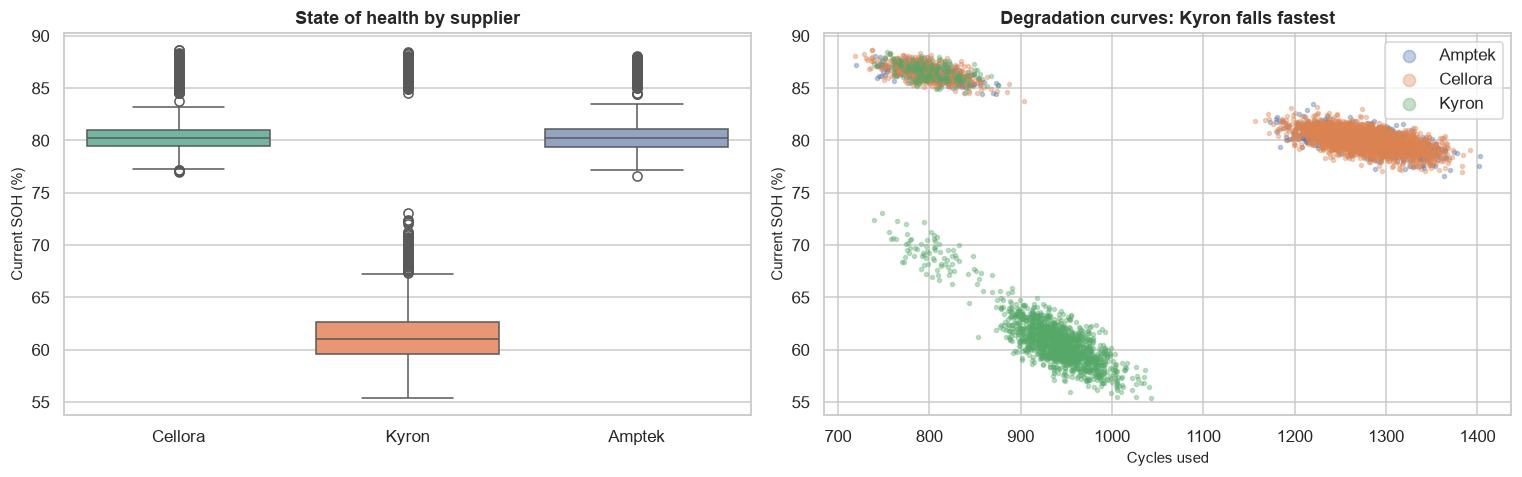

Degradation per 100 cycles (pp):
supplier
Amptek    1.518
Cellora   1.515
Kyron     3.814


In [19]:
b = batteries.copy()
b['cycles'] = b.uses
b['deg_per_cycle'] = (b.initial_soh_pct - b.current_soh_pct) / b.cycles.clip(lower=1)
b['retired'] = b.retired_date.notna()
sup = b.groupby('supplier', observed=True).agg(packs=('battery_id','size'),
        soh=('current_soh_pct','mean'), cycles=('cycles','mean'), retired_rate=('retired','mean'),
        deg_per_100=('deg_per_cycle', lambda s: s.mean()*100),
        capex_cr=('purchase_cost_inr', lambda s: s.sum()/1e7),
        cost_per_use=('cost_per_use','mean'))
display(sup.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=b, x='supplier', y='current_soh_pct', ax=ax[0], palette='Set2')
ax[0].set_title('State of health by supplier'); ax[0].set_ylabel('Current SOH (%)'); ax[0].set_xlabel('')
for s, g in b.groupby('supplier', observed=True):
    ax[1].scatter(g.cycles, g.current_soh_pct, s=7, alpha=.35, label=s)
ax[1].set_xlabel('Cycles used'); ax[1].set_ylabel('Current SOH (%)')
ax[1].set_title('Degradation curves: Kyron falls fastest'); ax[1].legend(markerscale=3)
save(fig, 'f10_battery_soh.png')
plt.show()
print('Degradation per 100 cycles (pp):')
print((b.groupby('supplier', observed=True).deg_per_cycle.mean()*100).round(3).to_string())

Kyron manufacturing lots:


,packs,commission,soh,cycles,retired,cost_cr
manufacturing_lot,,,,,,
KY-2407,480,2024-07-01,60.990,934.780,0.990,1.640
KY-2408,500,2024-08-01,61.050,934.270,0.980,1.710
KY-2409,481,2024-09-04,60.920,936.080,0.980,1.610
KY-2410,17,2024-10-02,86.260,792.060,0.000,0.120
KY-2411,21,2024-11-01,86.590,805.810,0.000,0.140
KY-2412,21,2024-12-01,86.470,799.860,0.000,0.140
KY-2413,24,2025-01-06,86.660,810.120,0.000,0.160
KY-2414,16,2025-02-01,86.500,810.060,0.000,0.110
KY-2415,24,2025-03-02,86.570,798.040,0.000,0.160


Retirements: 1438 packs, Rs 4.79 cr, mean SOH 60.8%, mean cycles 937


,swaps,km,kwh,revenue,wear,cm
soh,,,,,,
<70,576882,51.800,1.760,61.110,35.730,-2.160
70-80,1426742,59.960,1.860,60.010,25.920,2.890
80-90,1582472,66.280,2.420,68.430,38.120,-6.080


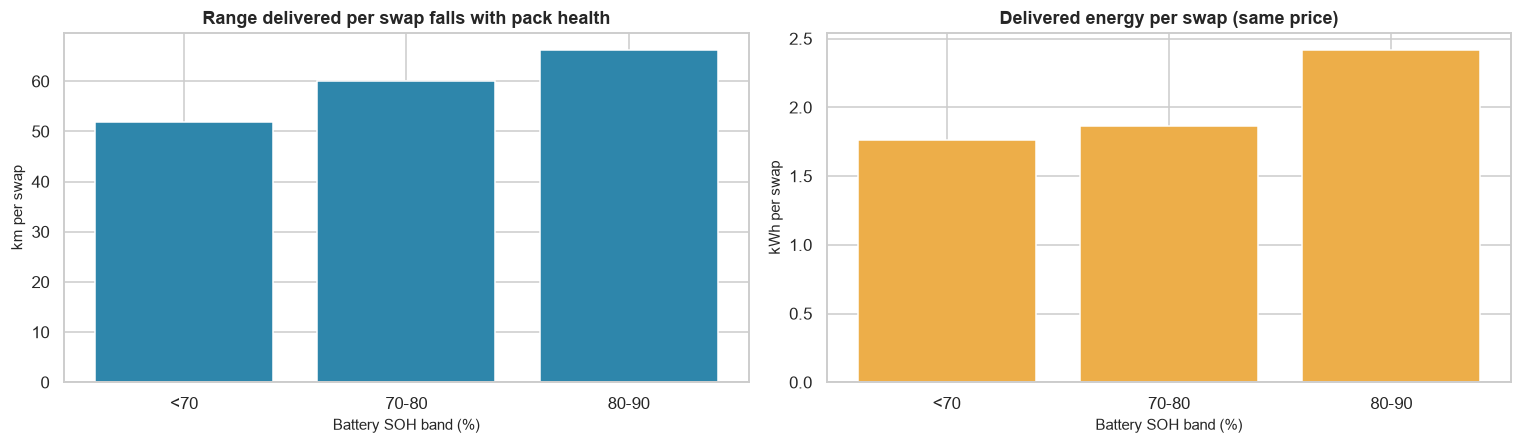

Range penalty low vs high SOH: 14 km (22%)


In [20]:
print('Kyron manufacturing lots:')
lots = b[b.supplier == 'Kyron'].groupby('manufacturing_lot', observed=True).agg(
        packs=('battery_id','size'), commission=('commission_date','min'),
        soh=('current_soh_pct','mean'), cycles=('cycles','mean'),
        retired=('retired','mean'), cost_cr=('purchase_cost_inr', lambda s: s.sum()/1e7))
display(lots.sort_values('commission').round(2))
print('Retirements: %d packs, Rs %.2f cr, mean SOH %.1f%%, mean cycles %.0f' % (
    int(b.retired.sum()), b[b.retired].purchase_cost_inr.sum()/1e7,
    b[b.retired].current_soh_pct.mean(), b[b.retired].cycles.mean()))

completed['soh'] = completed.battery_out_id.map(b.set_index('battery_id').current_soh_pct)
sb = pd.cut(completed.soh, [0,70,80,90,95,100], labels=['<70','70-80','80-90','90-95','95+'])
rng = completed.groupby(sb, observed=True).agg(swaps=('event_id','size'),
        km=('km_clean','mean'), kwh=('energy_to_recharge_kwh','mean'),
        revenue=('amount_charged_inr','mean'), wear=('wear_cost','mean'), cm=('cm','mean'))
display(rng.round(2))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(rng.index.astype(str), rng.km, color='#2e86ab')
ax[0].set_title('Range delivered per swap falls with pack health')
ax[0].set_ylabel('km per swap'); ax[0].set_xlabel('Battery SOH band (%)')
ax[1].bar(rng.index.astype(str), rng.kwh, color='#edae49')
ax[1].set_title('Delivered energy per swap (same price)')
ax[1].set_ylabel('kWh per swap'); ax[1].set_xlabel('Battery SOH band (%)')
save(fig, 'f11_range_soh.png')
plt.show()
print('Range penalty low vs high SOH: %.0f km (%.0f%%)' % (
    rng.km.iloc[-1]-rng.km.iloc[0], (1-rng.km.iloc[0]/rng.km.iloc[-1])*100))

In [21]:
completed['pack_type'] = completed.battery_out_id.map(b.set_index('battery_id').pack_type)
pt = completed.groupby('pack_type', observed=True).agg(swaps=('event_id','size'),
        revenue=('amount_charged_inr','mean'), energy=('energy_cost','mean'),
        wear=('wear_cost','mean'), cm=('cm','mean'), km=('km_clean','mean'))
pt['wear_pct_rev'] = pt.wear/pt.revenue
display(pt.round(2))
print('Kyron: %.1f%% SOH after %.0f cycles | peers: %.1f%% after %.0f cycles' % (
    b[b.supplier=='Kyron'].current_soh_pct.mean(), b[b.supplier=='Kyron'].cycles.mean(),
    b[b.supplier!='Kyron'].current_soh_pct.mean(), b[b.supplier!='Kyron'].cycles.mean()))
print('Retired asset base: Rs %.2f cr of Rs %.2f cr total' % (
    b[b.retired].purchase_cost_inr.sum()/1e7, b.purchase_cost_inr.sum()/1e7))

,swaps,revenue,energy,wear,cm,km,wear_pct_rev
pack_type,,,,,,,
2W_2.1kWh,3213862,59.760,17.020,27.030,2.340,58.170,0.450
3W_4.8kWh,372234,99.640,40.890,83.360,-38.320,89.630,0.840


Kyron: 63.7% SOH after 921 cycles | peers: 80.9% after 1206 cycles
Retired asset base: Rs 4.79 cr of Rs 24.32 cr total


**Q4 answer.** The fleet has a **supplier and lot quality problem**:

- **Kyron averages 63.7% SOH after 921 cycles, versus 80.9% for peers after 1,206 cycles** — worse
  health despite 25% fewer cycles. Its degradation is **0.038 pp per cycle versus 0.015**.
- The damage is concentrated in **lots KY-2407/08/09 (1,461 packs at ~61% SOH)**, 98–99% retired after
  ~940 cycles, commissioned Jul–Sep 2024.
- **All 1,438 retirements are Kyron**, costing **₹4.79 cr** — 20% of the ₹24.3 cr asset base. Only 200
  Kyron packs remain in service.
- SOH is visible to riders: packs below 70% deliver **52 km and 1.76 kWh per swap** versus **66 km and
  2.42 kWh** at 80–90% SOH, at the same price. This is the source of the `low_range` complaints.
- **3W packs are structurally unprofitable**: ₹83 wear + ₹41 energy against ₹100 revenue gives
  **−₹38 CM per swap**. 3W is 10.4% of swaps and **−₹1.43 cr** of contribution.

Contract implication: buy **cycles delivered**, not nameplate kWh. A pack that is 15% cheaper but
delivers 60% of the cycles is roughly twice as expensive per swap.

## 9. Question 5 — Pricing and partner economics

Three pricing events sit inside the window: the **July-2024 list-price rise**, the **peak/off-peak
pilot from October 2024 in Bengaluru and Pune**, and **contract amendments with fleet partners**
(notably ZipDrop, November 2024). We evaluate the first two against comparison groups and the third
with a before/after difference-in-differences against other partners.

,swaps,list_price,discount,paid,share
tariff_code,,,,,
PARTNER,2367732,69.700,8.810,61.690,0.660
STD,1019623,66.210,0.000,66.210,0.280
OFFPEAK,34833,67.480,0.000,59.480,0.010
PEAK,163908,67.500,0.000,82.500,0.050


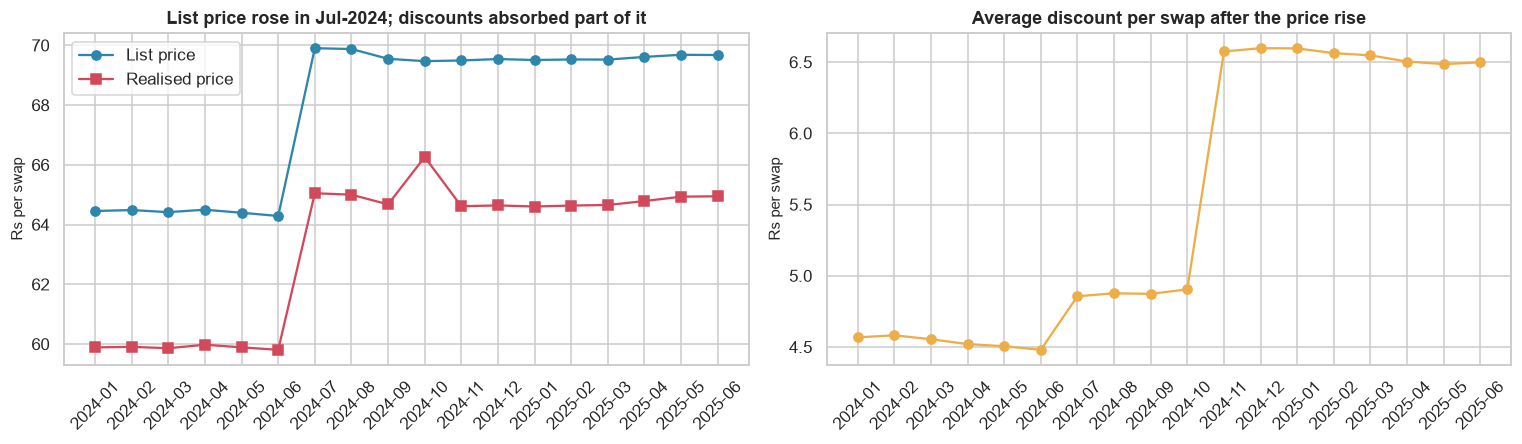

Before/after Jul-2024: realised 59.81 -> 65.05 (+8.8%), discount 4.48 -> 4.86


In [22]:
lad = completed.groupby('tariff_code', observed=True).agg(swaps=('event_id','size'),
        list_price=('list_price_inr','mean'), discount=('discount_inr','mean'),
        paid=('amount_charged_inr','mean'), share=('event_id', lambda s: len(s)/len(completed)))
display(lad.round(2))

mprice = completed.groupby('month', observed=True).agg(list=('list_price_inr','mean'),
        paid=('amount_charged_inr','mean'), disc=('discount_inr','mean'))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(mprice.index, mprice.list, marker='o', label='List price', color='#2e86ab')
ax[0].plot(mprice.index, mprice.paid, marker='s', label='Realised price', color='#d1495b')
ax[0].set_title('List price rose in Jul-2024; discounts absorbed part of it')
ax[0].set_ylabel('Rs per swap'); ax[0].tick_params(axis='x', rotation=45); ax[0].legend()
ax[1].plot(mprice.index, mprice.disc, marker='o', color='#edae49')
ax[1].set_title('Average discount per swap after the price rise')
ax[1].set_ylabel('Rs per swap'); ax[1].tick_params(axis='x', rotation=45)
save(fig, 'f12_price_discount.png')
plt.show()
print('Before/after Jul-2024: realised %.2f -> %.2f (+%.1f%%), discount %.2f -> %.2f' % (
    mprice.paid.loc['2024-06'], mprice.paid.loc['2024-07'],
    (mprice.paid.loc['2024-07']/mprice.paid.loc['2024-06']-1)*100,
    mprice.disc.loc['2024-06'], mprice.disc.loc['2024-07']))

swaps  peak_share   paid   list  disc
grp     period                                         
control post    1572733       0.528 63.108 69.500 6.392
        pre      759598       0.524 62.041 66.642 4.601
pilot   post     818591       0.515 68.268 69.690 6.398
        pre      435174       0.538 61.810 66.603 4.793

DiD peak-hour share: -2.75 pp (pilot 53.8% -> 51.5%; control 52.4% -> 52.8%)
Pilot post price Rs 68.27 vs control Rs 63.11


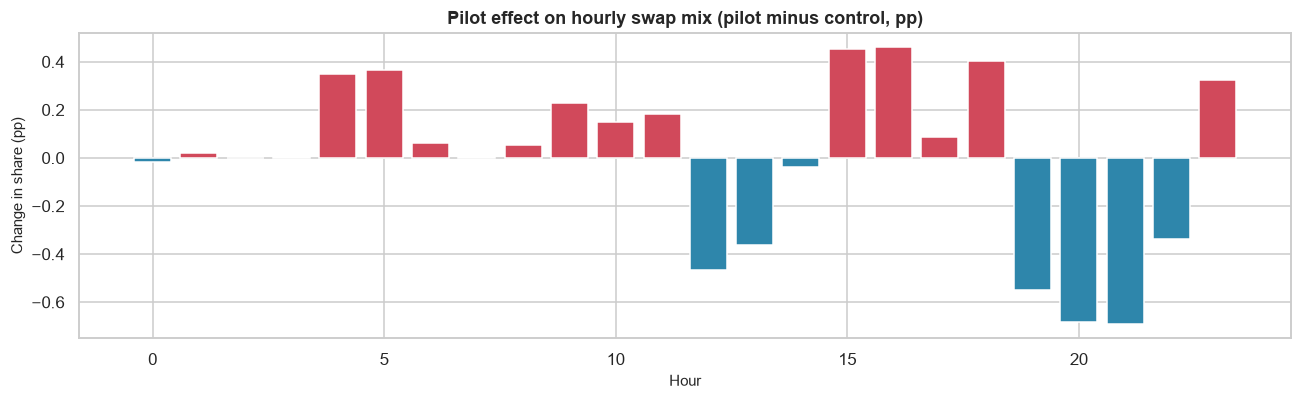

In [23]:
c = completed.copy()
c['grp'] = np.where(c.city.isin(['Bengaluru','Pune']), 'pilot', 'control')
c['period'] = np.where(c.event_ts >= '2024-10-01', 'post', 'pre')
c['peak_hour'] = c.hour.isin([12,13,19,20,21])
did = c.groupby(['grp','period'], observed=True).agg(swaps=('event_id','size'),
        peak_share=('peak_hour','mean'), paid=('amount_charged_inr','mean'),
        list=('list_price_inr','mean'), disc=('discount_inr','mean'))
display(did.round(3))
p = did.peak_share.unstack('grp')
effect = (p.loc['post','pilot']-p.loc['pre','pilot']) - (p.loc['post','control']-p.loc['pre','control'])
print('DiD peak-hour share: %+.2f pp (pilot %.1f%% -> %.1f%%; control %.1f%% -> %.1f%%)' % (
    effect*100, p.loc['pre','pilot']*100, p.loc['post','pilot']*100,
    p.loc['pre','control']*100, p.loc['post','control']*100))
print('Pilot post price Rs %.2f vs control Rs %.2f' % (
    did.loc[('pilot','post'),'paid'], did.loc[('control','post'),'paid']))

hs = c.groupby(['grp','period','hour'], observed=True).size().rename('n').reset_index()
hs['share'] = hs.n / hs.groupby(['grp','period'], observed=True).n.transform('sum')
piv = hs.pivot_table(index='hour', columns=['grp','period'], values='share')
diff = (piv[('pilot','post')] - piv[('pilot','pre')]) - (piv[('control','post')] - piv[('control','pre')])
diff = diff*100
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(diff.index, diff.values, color=np.where(diff.values < 0, '#2e86ab', '#d1495b'))
ax.set_title('Pilot effect on hourly swap mix (pilot minus control, pp)')
ax.set_xlabel('Hour'); ax.set_ylabel('Change in share (pp)')
save(fig, 'f13_pilot_hourly.png')
plt.show()

,swaps,riders,rev_ps,disc_ps,cm_ps,cm_cr,share
partner,,,,,,,
Independent,1218364,7598,68.210,0.000,6.460,0.790,0.340
ZipDrop,549256,2377,52.070,14.620,-10.330,-0.570,0.150
FeastFly,516273,2704,62.030,6.640,0.250,0.010,0.140
ParcelNest,296179,1760,56.510,9.940,-5.090,-0.150,0.080
Swiggle Go,237595,1253,59.300,7.330,-3.000,-0.070,0.070
CargoTuk,131324,864,99.460,8.640,-38.480,-0.510,0.040
QuickCart,127930,531,62.010,5.920,1.130,0.010,0.040
RideMitra,119473,607,62.720,3.960,1.470,0.020,0.030
DabbaXpress,92009,488,63.610,5.320,2.150,0.020,0.030


swaps  rev_ps  disc_ps   cm_ps
group              post_amend                                  
All other partners False       1198353  63.530    4.150  -6.290
                   True        1838487  67.680    4.280   3.510
ZipDrop            False        212939  57.480    7.840  -8.480
                   True         336317  48.640   18.920 -11.500

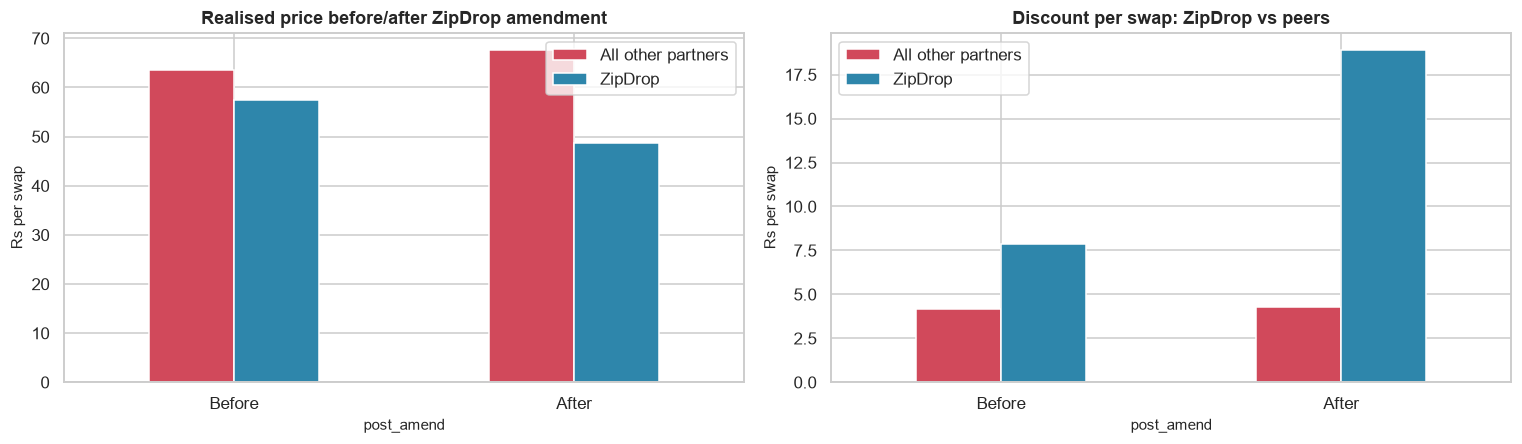

ZipDrop revenue/swap: 57.48 -> 48.64 | peers 63.53 -> 67.68
Relative give-up: Rs 12.99/swap | post-amendment swaps 336317 | annualised Rs 0.66 cr


In [24]:
c['partner'] = c.partner_name.fillna('Independent')
part = c.groupby('partner', observed=True).agg(swaps=('event_id','size'),
        riders=('rider_id','nunique'), rev_ps=('amount_charged_inr','mean'),
        disc_ps=('discount_inr','mean'), cm_ps=('cm','mean'),
        cm_cr=('cm', lambda s: s.sum()/1e7))
part['share'] = part.swaps/part.swaps.sum()
display(part.sort_values('swaps', ascending=False).round(2))

c['post_amend'] = c.event_ts >= '2024-11-01'
zp = c.copy(); zp['group'] = np.where(zp.partner == 'ZipDrop', 'ZipDrop', 'All other partners')
zd = zp.groupby(['group','post_amend'], observed=True).agg(swaps=('event_id','size'),
        rev_ps=('amount_charged_inr','mean'), disc_ps=('discount_inr','mean'), cm_ps=('cm','mean'))
display(zd.round(2))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
zd = zd.reset_index()
zd['post_amend'] = zd.post_amend.map({False:'Before', True:'After'})
zd = zd.set_index(['group','post_amend'])
zd = zd.reindex(['Before','After'], level='post_amend')
zd.rev_ps.unstack().T.plot.bar(ax=ax[0], color=['#d1495b','#2e86ab'])
ax[0].set_title('Realised price before/after ZipDrop amendment'); ax[0].set_ylabel('Rs per swap')
ax[0].tick_params(axis='x', rotation=0); ax[0].legend(title='')
zd.disc_ps.unstack().T.plot.bar(ax=ax[1], color=['#d1495b','#2e86ab'])
ax[1].set_title('Discount per swap: ZipDrop vs peers'); ax[1].set_ylabel('Rs per swap')
ax[1].tick_params(axis='x', rotation=0); ax[1].legend(title='')
save(fig, 'f14_partner_zipdrop.png')
plt.show()

pre = zd.loc[('ZipDrop','Before')]; post = zd.loc[('ZipDrop','After')]
ppre = zd.loc[('All other partners','Before')]; ppost = zd.loc[('All other partners','After')]
rel = (post.rev_ps-pre.rev_ps) - (ppost.rev_ps-ppre.rev_ps)
print('ZipDrop revenue/swap: %.2f -> %.2f | peers %.2f -> %.2f' % (
    pre.rev_ps, post.rev_ps, ppre.rev_ps, ppost.rev_ps))
print('Relative give-up: Rs %.2f/swap | post-amendment swaps %d | annualised Rs %.2f cr' % (
    abs(rel), int(post.swaps), abs(rel)*post.swaps/8*12/1e7))

**Q5 answer.** Pricing power exists, but it is being given away through discounts.

- **The July-2024 rise stuck.** Realised price rose ₹59.9 → ₹65.0 (+8.7%) with no break in volume.
- **The peak pilot worked modestly.** Peak-hour share fell **2.75 pp more** in pilot cities than
  control (53.8% → 51.5% versus 52.4% → 52.8%), and pilot cities realised **₹68.27 versus ₹63.11** in
  control after launch.
- **Discounts doubled over the window.** Average discount rose ₹4.5 → ₹6.1 (June to July alone: ₹4.5 → ₹4.9); **ZipDrop's amendment lifted its
  contractual discount from 12% to 28%**. Its realised price fell **₹57.48 → ₹48.64** while peers rose
  **₹63.53 → ₹67.68** — a **relative give-up of ₹12.99/swap**, about **₹0.66 cr annualised** on
  post-amendment volume. ZipDrop contributes **−₹0.57 cr** in-window.
- **Partner economics are bimodal.** Independent riders earn **+₹6.46/swap**; small 2W partners
  +₹0.2 to +₹2.2; **3W cargo partners lose ₹37–38/swap** (CargoTuk, HaulKing); ZipDrop loses ₹10.33;
  ParcelNest loses ₹5.09. The leak is two segments — 3W and deep-discount fleets — not one account.

## 10. Question 6 — Root cause of new-rider retention

**Design.** Acquisition = rider's first event; features = first 30 days; outcome `ret_d90` = any
completed swap in days 31–90. Riders acquired after 31 March 2025 are excluded because their window
is truncated. We separate **usage intensity** from **failure exposure** by stratification and a
logistic model with city, vehicle, partner and channel controls.

In [25]:
first = (swaps.groupby('rider_id', observed=True)
          .agg(first_ts=('event_ts','min'), first_type=('event_type','first'),
               first_city=('city','first'), first_station=('station_id','first')))
first['first_type'] = first.first_type.astype(str)
fm = first.first_ts

ev = swaps[['rider_id','event_ts','event_type','queue_wait_sec']].copy()
ev['first_ts'] = ev.rider_id.map(fm)
ev['day'] = (ev.event_ts - ev.first_ts).dt.total_seconds()/86400
w = ev[ev.day.between(0, 30, inclusive='left')].copy()
w['is_swap'] = (w.event_type == 'swap_completed').astype('int8')
feat = w.groupby('rider_id', observed=True).agg(n_events=('is_swap','size'),
        n_swaps=('is_swap','sum'), queue_med=('queue_wait_sec','median'))
feat['fail_rate'] = 1 - feat.n_swaps/feat.n_events

cmps = swaps.loc[swaps.event_type == 'swap_completed', ['rider_id','event_ts']].copy()
cmps['day'] = (cmps.event_ts - cmps.rider_id.map(fm)).dt.total_seconds()/86400
m2 = set(cmps.loc[cmps.day.gt(30) & cmps.day.le(60), 'rider_id'])
m3 = set(cmps.loc[cmps.day.gt(60) & cmps.day.le(90), 'rider_id'])
d90 = set(cmps.loc[cmps.day.gt(30) & cmps.day.le(90), 'rider_id'])

rt = first.join(feat)
rt['m2'] = rt.index.isin(m2).astype('int8')
rt['m3'] = rt.index.isin(m3).astype('int8')
rt['d90'] = rt.index.isin(d90).astype('int8')
rt = rt.join(riders.set_index('rider_id')[['home_city_clean','signup_channel','vehicle_class','partner_id','plan_type']])
rt['partner'] = np.where(rt.partner_id.notna(), 'partner', 'independent')
rt['cohort'] = rt.first_ts.dt.to_period('M').astype(str)
mature = rt[rt.first_ts < '2025-04-01'].copy()
print('Riders with events: %d | mature cohort: %d' % (len(rt), len(mature)))
print('M1 active %.1f%% | M2 %.1f%% | M3 %.1f%% | 90-day return %.1f%%' % (
    (mature.n_swaps>0).mean()*100, mature.m2.mean()*100, mature.m3.mean()*100, mature.d90.mean()*100))

Riders with events: 19941 | mature cohort: 16289
M1 active 100.0% | M2 87.2% | M3 81.9% | 90-day return 89.1%


,riders,m2,m3,d90,swaps30,fail30
cohort,,,,,,
2024-01,4182,0.916,0.859,0.926,26.637,0.046
2024-02,568,0.852,0.808,0.877,25.104,0.048
2024-03,600,0.885,0.810,0.893,25.145,0.056
2024-04,660,0.824,0.771,0.852,24.524,0.093
2024-05,717,0.791,0.729,0.816,23.455,0.116
2024-06,717,0.837,0.794,0.869,24.116,0.080
2024-07,804,0.879,0.807,0.897,25.340,0.047
2024-08,856,0.875,0.828,0.894,26.518,0.048
2024-09,869,0.857,0.809,0.881,27.948,0.048


Activity by month since acquisition and acquisition year:


year,2024,2025
m_idx,,
1,1.000,1.000
2,0.874,0.863
3,0.821,0.809
4,0.782,0.752
5,0.737,0.512
6,0.740,0.239


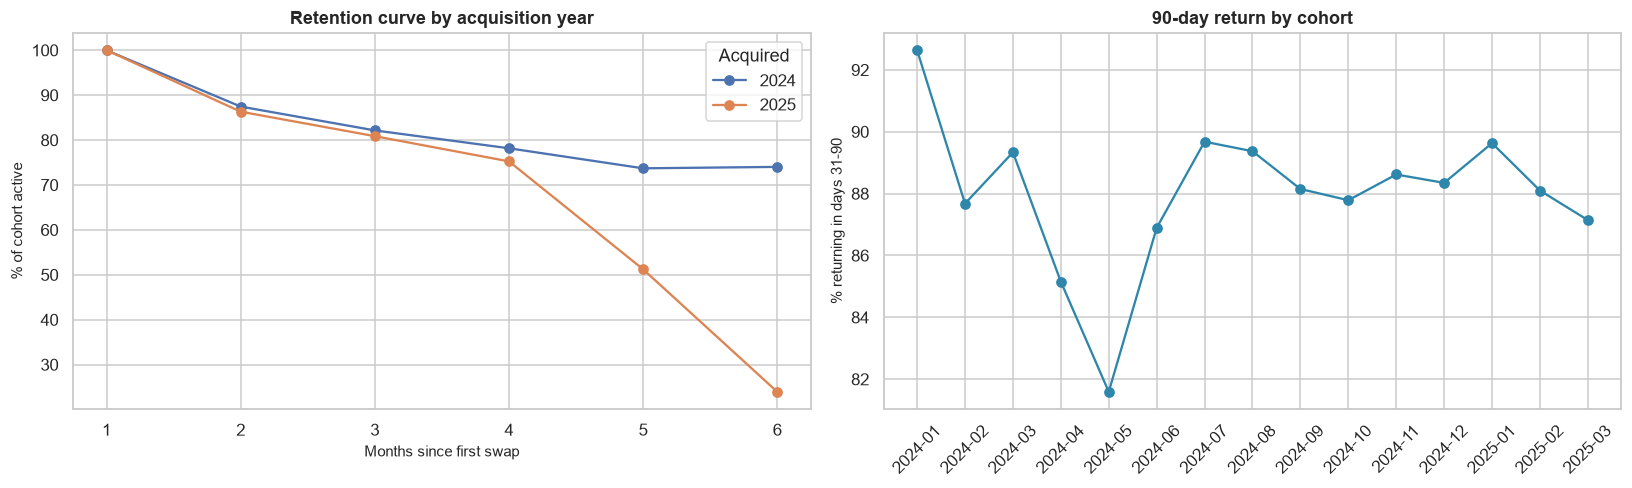

In [26]:
coh = mature.groupby('cohort', observed=True).agg(riders=('d90','size'), m2=('m2','mean'),
        m3=('m3','mean'), d90=('d90','mean'), swaps30=('n_swaps','mean'), fail30=('fail_rate','mean'))
display(coh.round(3))

cmps['m_idx'] = np.ceil(cmps.day.clip(lower=0)/30).clip(1, 6).astype(int)
ca = cmps.merge(mature[['cohort','first_ts']], left_on='rider_id', right_index=True, how='inner')
ca['year'] = ca.first_ts.dt.year
num = ca.groupby(['year','m_idx'], observed=True).rider_id.nunique().rename('active').reset_index()
den = mature.groupby(mature.first_ts.dt.year, observed=True).size().rename('size').reset_index()
den.columns = ['year','cohort_size']
curve = num.merge(den, on='year'); curve['rate'] = curve.active/curve.cohort_size
curve = curve.pivot(index='m_idx', columns='year', values='rate')
print('Activity by month since acquisition and acquisition year:')
display(curve.round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for y in curve.columns:
    ax[0].plot(curve.index, curve[y]*100, marker='o', label=str(y))
ax[0].set_title('Retention curve by acquisition year'); ax[0].set_xlabel('Months since first swap')
ax[0].set_ylabel('% of cohort active'); ax[0].legend(title='Acquired')
ax[1].plot(coh.index, coh.d90*100, marker='o', color='#2e86ab')
ax[1].set_title('90-day return by cohort'); ax[1].set_ylabel('% returning in days 31-90')
ax[1].tick_params(axis='x', rotation=45)
save(fig, 'f15_cohort_retention.png')
plt.show()

In [27]:
mature['sw_b'] = pd.cut(mature.n_swaps, [0,5,20,60,1000], labels=['1-5','6-20','21-60','60+'])
mature['f_b'] = pd.cut(mature.fail_rate, [-.01,0,.1,.25,1.01], labels=['0%','0-10%','10-25%','>25%'])
print('90-day return by usage intensity and first-month failure rate:')
display(mature.pivot_table(index='sw_b', columns='f_b', values='d90', aggfunc='mean', observed=True).round(3))
print('Rider counts:')
display(mature.pivot_table(index='sw_b', columns='f_b', values='d90', aggfunc='count', observed=True))
print('Marginal rates:')
print(mature.groupby('sw_b', observed=True).d90.agg(['mean','size']).round(3).to_string())
print(mature.groupby('f_b', observed=True).d90.agg(['mean','size']).round(3).to_string())

90-day return by usage intensity and first-month failure rate:


f_b,0%,0-10%,10-25%,>25%
sw_b,,,,
1-5,0.452,NaN,0.353,0.323
6-20,0.488,0.704,0.641,0.578
21-60,0.963,0.963,0.940,0.944
60+,NaN,0.500,NaN,NaN


Rider counts:


f_b,0%,0-10%,10-25%,>25%
sw_b,,,,
1-5,365.000,NaN,68.000,65.000
6-20,699.000,888.000,843.000,102.000
21-60,"3,608.000","8,261.000","1,367.000",18.000
60+,NaN,2.000,NaN,NaN


Marginal rates:
       mean   size
sw_b              
1-5   0.422    498
6-20  0.618   2532
21-60 0.960  13254
60+   0.500      2
        mean  size
f_b               
0%     0.852  4672
0-10%  0.937  9151
10-25% 0.812  2278
>25%   0.516   188


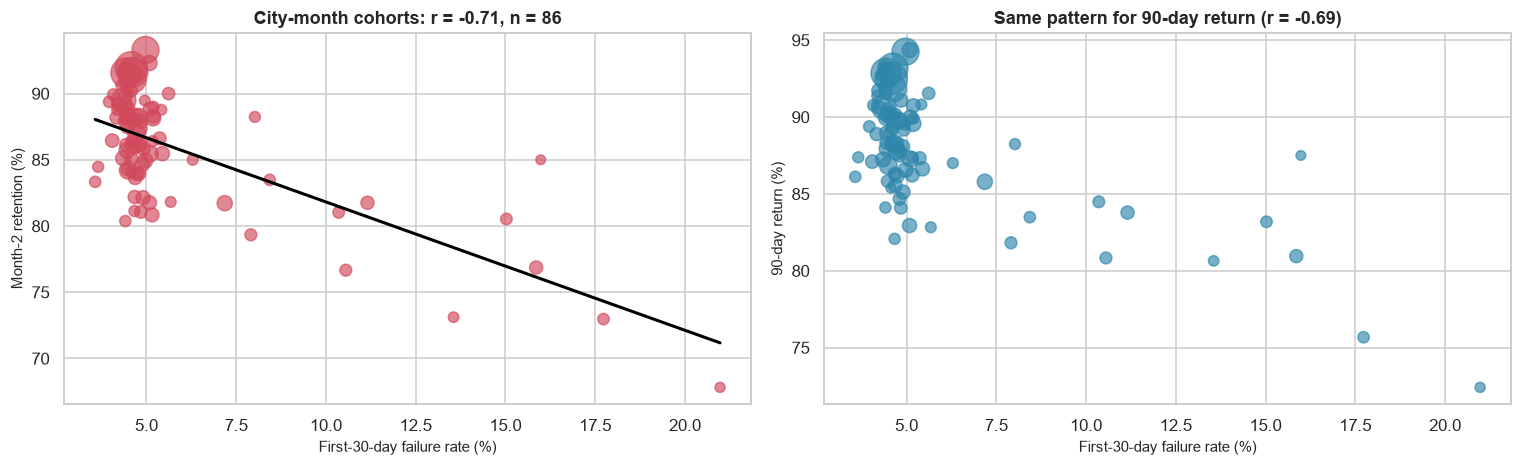

p-value 2.36e-14 | +1 pp failure -> -0.97 pp lower M2
Cohorts >10% failure: M2 77.3% vs 87.0% below 6%


In [ ]:
from scipy import stats
g = (mature.groupby(['first_city','cohort'], observed=True)
     .agg(n=('d90','size'), m2=('m2','mean'), fail30=('fail_rate','mean'), d90=('d90','mean'))
     .reset_index())
g = g[g.n >= 80]
r, pval = stats.pearsonr(g.fail30, g.m2)
slope, intercept = np.polyfit(g.fail30, g.m2, 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].scatter(g.fail30*100, g.m2*100, s=g.n/2, alpha=.65, color='#d1495b')
xs = np.linspace(g.fail30.min(), g.fail30.max(), 50)
ax[0].plot(xs*100, (intercept+slope*xs)*100, color='black', lw=2)
ax[0].set_xlabel('First-30-day failure rate (%)'); ax[0].set_ylabel('Month-2 retention (%)')
ax[0].set_title('City-month cohorts: r = %.2f, n = %d' % (r, len(g)))
ax[1].scatter(g.fail30*100, g.d90*100, s=g.n/2, alpha=.65, color='#2e86ab')
ax[1].set_xlabel('First-30-day failure rate (%)'); ax[1].set_ylabel('90-day return (%)')
ax[1].set_title('Same pattern for 90-day return (r = %.2f)' % stats.pearsonr(g.fail30, g.d90)[0])
save(fig, 'f16_cohort_failure_scatter.png')
plt.show()
print('p-value %.2e | +1 pp failure -> %.2f pp lower M2' % (pval, slope))
print('Cohorts >10%% failure: M2 %.1f%% vs %.1f%% below 6%%' % (
    g[g.fail30>.10].m2.mean()*100, g[g.fail30<.06].m2.mean()*100)) 

Logit n=16286  pseudo-R2=0.293  base rate=0.891
                                          coef     p  odds_ratio
Intercept                                4.361 0.000      78.370
C(f_b, Treatment("0-10%"))[T.0%]        -0.351 0.000       0.704
C(f_b, Treatment("0-10%"))[T.10-25%]    -0.433 0.000       0.648
C(f_b, Treatment("0-10%"))[T.>25%]      -0.613 0.001       0.542
C(sw_b, Treatment("21-60"))[T.1-5]      -3.761 0.000       0.023
C(sw_b, Treatment("21-60"))[T.6-20]     -3.208 0.000       0.040
C(sw_b, Treatment("21-60"))[T.60+]      -2.880 0.042       0.056
C(first_city)[T.Delhi NCR]              -0.622 0.000       0.537
C(first_city)[T.Hyderabad]              -0.662 0.000       0.516
C(first_city)[T.Jaipur]                 -0.767 0.000       0.464
C(first_city)[T.Mumbai]                 -0.407 0.000       0.666
C(first_city)[T.Pune]                   -0.663 0.000       0.515
C(vehicle_class)[T.3W]                   1.377 0.000       3.964
C(partner)[T.partner]                   -0

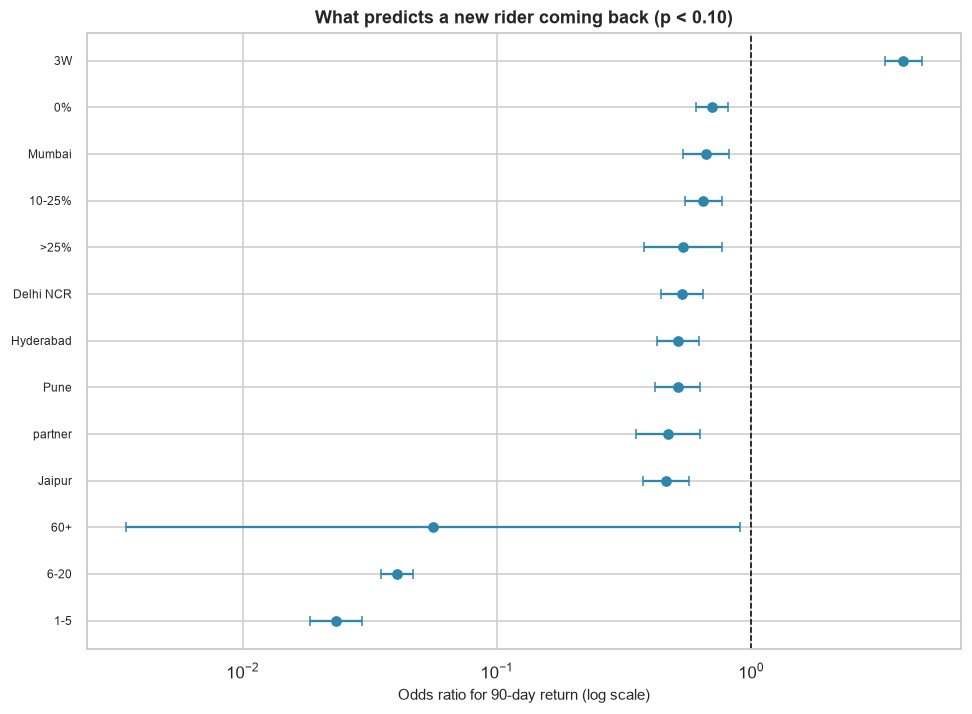

In [29]:
import statsmodels.formula.api as smf
mod = mature.dropna(subset=['n_swaps','f_b','first_city','partner']).copy()
for col in ['first_city','signup_channel','vehicle_class','partner','f_b','sw_b']:
    mod[col] = mod[col].astype(str)
formula = ('d90 ~ C(f_b, Treatment("0-10%")) + C(sw_b, Treatment("21-60")) '
           '+ C(first_city) + C(vehicle_class) + C(partner) + C(signup_channel)')
res = smf.logit(formula, data=mod).fit(disp=0)
print('Logit n=%d  pseudo-R2=%.3f  base rate=%.3f' % (res.nobs, res.prsquared, mod.d90.mean()))
tab = pd.DataFrame({'coef': res.params, 'p': res.pvalues, 'odds_ratio': np.exp(res.params)})
print(tab.round(3).to_string())

plot_df = tab.drop('Intercept').copy()
plot_df = plot_df[plot_df.p < 0.10].sort_values('odds_ratio')
fig, ax = plt.subplots(figsize=(9, 0.42*len(plot_df)+1.2))
ci = res.conf_int()
ax.errorbar(plot_df.odds_ratio, range(len(plot_df)),
            xerr=[plot_df.odds_ratio - np.exp(ci.loc[plot_df.index,0]),
                  np.exp(ci.loc[plot_df.index,1]) - plot_df.odds_ratio],
            fmt='o', color='#2e86ab', capsize=3)
ax.axvline(1, color='black', ls='--', lw=1)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels([i.split('T.')[-1].replace(']','').replace(')','') for i in plot_df.index], fontsize=8)
ax.set_xscale('log'); ax.set_xlabel('Odds ratio for 90-day return (log scale)')
ax.set_title('What predicts a new rider coming back (p < 0.10)')
save(fig, 'f17_retention_odds.png')
plt.show()

**Q6 answer — stable retention, two different drivers.**

*Is retention falling?* **No secular collapse.** 90-day return is **89.1%** overall. Cohort values:
92.6% (Jan-24), 85.2% (Apr-24), **81.6% (May-24)**, 86.9% (Jun-24), 87.1% (Mar-25). The dips are
seasonal and coincide with failure spikes, not with acquisition mix (first-month usage is flat at
23–28 swaps). Post-March-2025 cohorts are excluded as truncated.

*Why do riders leave?* **Habit is primary; failure is the accelerant.**
- 90-day return by first-month swaps: **1–5 → 42.2%**, 6–20 → 61.8%, **21–60 → 96.0%**. In the logit,
  1–5 swaps has **OR 0.023** versus 21–60.
- Conditional on usage, failure matters: within 21–60 swaps, >10% first-month failure cuts return
  from 96.3% to 94.0%; the >25% failure group returns at **51.6%** overall.
- Across **86 city-month cohorts**, first-month failure explains **50% of month-2 retention variance
  (r = −0.71)**; +1 pp failure → **−0.97 pp** month-2 retention. Cohorts above 10% failure retain
  **77.3%** in month 2 versus **87.0%** below 6%.
- Controls: failure 10–25% OR 0.65 and >25% OR 0.54; 3W OR 3.96 (commercial riders are stickier);
  partner-onboarded OR 0.47; every city is worse than Bengaluru (Jaipur OR 0.46).
- A failed *first* attempt matters less (84% vs 89%) than a failure-heavy first month.

**Implication:** retention strategy must do two things — drive first-month usage to ~20+ swaps, and
protect the first 30 days from failure. Fixing only one will not move the curve much.

## 11. Optional deep dives

### 11.1 Expansion-wave effectiveness

Two waves opened after launch: **Wave 1 (Aug–Sep 2024, 30 stations)** and **Wave 2 (Feb 2025, 30
stations)**. We test whether new capacity went where demand was constrained and whether it relieved
incumbent stations.

,stations,attempts,fail,charge,per_slot_day,cm_ps
expansion_wave,,,,,,
Launch,90,3068385,0.061,79.844,4.614,-2.897
Wave1_2024H2,30,500998,0.049,59.161,4.099,-3.225
Wave2_2025H1,30,245019,0.050,42.168,5.830,-0.610


expansion_wave,Launch,Wave1_2024H2,Wave2_2025H1
city,,,
Bengaluru,4.750,4.230,5.260
Delhi NCR,5.040,3.880,5.990
Hyderabad,4.540,4.800,7.240
Jaipur,5.080,3.480,8.810
Mumbai,4.230,4.330,4.230
Pune,3.940,3.820,3.710


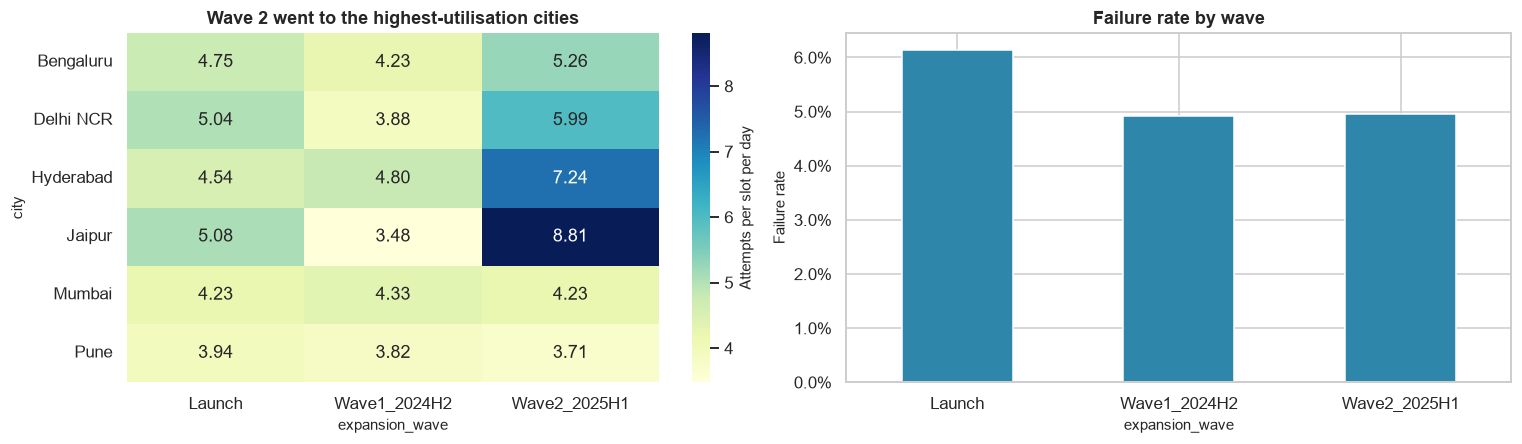

Launch-station failure, Jul-Sep vs Nov-Mar, by city:


  Bengaluru  0.042 -> 0.043 (+0.002)


  Delhi NCR  0.045 -> 0.043 (-0.002)


  Hyderabad  0.043 -> 0.043 (-0.001)


  Jaipur     0.043 -> 0.042 (-0.000)


  Mumbai     0.043 -> 0.044 (+0.001)


  Pune       0.044 -> 0.043 (-0.001)


In [30]:
wave = st.groupby('expansion_wave', observed=True).agg(stations=('station_id','size'),
        attempts=('attempts','sum'), fail=('fail','mean'), charge=('charge_min','mean'),
        per_slot_day=('per_slot_day','mean'), cm_ps=('cm_ps','mean'))
display(wave.round(3))
util = st.pivot_table(index='city', columns='expansion_wave', values='per_slot_day', aggfunc='mean')
display(util.round(2))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
sns.heatmap(util, annot=True, fmt='.2f', cmap='YlGnBu', ax=ax[0],
            cbar_kws={'label':'Attempts per slot per day'})
ax[0].set_title('Wave 2 went to the highest-utilisation cities')
wave[['fail']].plot.bar(ax=ax[1], color='#2e86ab', legend=False)
ax[1].set_title('Failure rate by wave'); ax[1].set_ylabel('Failure rate')
ax[1].tick_params(axis='x', rotation=0)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
save(fig, 'f18_expansion_waves.png')
plt.show()
print('Launch-station failure, Jul-Sep vs Nov-Mar, by city:')
for city in sorted(st.city.dropna().unique()):
    pre = swaps[(swaps.city==city) & (swaps.month.between('2024-07','2024-09')) &
                (swaps.expansion_wave=='Launch')].is_failed.mean()
    post = swaps[(swaps.city==city) & (swaps.month.between('2024-11','2025-03')) &
                 (swaps.expansion_wave=='Launch')].is_failed.mean()
    print('  %-10s %.3f -> %.3f (%+.3f)' % (city, pre, post, post-pre))

In [31]:
def norm(s): return re.sub(r'[^a-z ]', ' ', str(s).lower())
def keyword_cat(t):
    if any(k in t for k in ['range','rnage','mileage',' km']): return 'low_range'
    if any(k in t for k in ['queue','line','wait','intezaar','lambi']): return 'long_queue'
    if any(k in t for k in ['no battery','battery nahi','charged battery','stock']): return 'no_battery_available'
    if any(k in t for k in ['surcharge','refund','amount','paisa','kata','billing','charge laga']): return 'billing_dispute'
    if any(k in t for k in ['app','qr','scan','otp','login']): return 'app_issue'
    return 'other'
t2 = tickets.copy()
t2['text_cat'] = t2.rider_comment.map(norm).map(keyword_cat)
print('Agreement: %.1f%%' % ((t2.category.astype(str) == t2.text_cat).mean()*100))
display(pd.crosstab(t2.category, t2.text_cat))
print('Sample Hinglish comments:')
for cat in ['billing_dispute','low_range','long_queue']:
    s = t2[t2.category == cat].rider_comment.dropna()
    print(' ', cat + ':')
    for x in s.sample(2, random_state=1): print('    -', str(x)[:110])
print('CSAT recorded on %.1f%% of tickets; mean by category:' % (t2.csat_score.notna().mean()*100))
print(t2.groupby('category').csat_score.agg(['count','mean']).round(2).to_string())

Agreement: 75.7%


text_cat,app_issue,billing_dispute,long_queue,low_range,no_battery_available,other
category,,,,,,
app_issue,5778,0,0,0,0,0
billing_dispute,0,4710,0,0,0,0
long_queue,0,0,5719,0,0,0
low_range,0,0,0,5279,0,1345
no_battery_available,0,0,2881,0,2283,6459
other,0,0,0,0,0,9460


Sample Hinglish comments:
  billing_dispute:
    - surcharge laga diya bina bataye
    - charged extra amount than usual
  low_range:
    - kal se range kam ho gaya hai battery ka
    - kal se rnage kam ho gaya hai battry ka
  long_queue:
    - queue itna lamba tha ki late ho gaya delivery mein
    - bahut lambi line thi swap ke liye
CSAT recorded on 34.4% of tickets; mean by category:
                      count  mean
category                         
app_issue              1943 3.540
billing_dispute        1617 3.570
long_queue             1991 3.510
low_range              2320 3.530
no_battery_available   3987 3.600
other                  3237 3.570


### 11.2 Anomalies worth flagging

In [32]:
print('Firmware / sync / connectivity vs failure:')
display(swaps.groupby(['station_firmware','sync_mode'], observed=True).agg(
    attempts=('event_id','size'), fail=('is_failed','mean')).round(3))
display(swaps.groupby('connectivity_tier', observed=True).agg(
    attempts=('event_id','size'), fail=('is_failed','mean'),
    offline_share=('sync_mode', lambda s: (s=='offline_batch').mean())).round(3))
print('Stations with persistent extreme failure:')
display(st.nlargest(12, 'fail')[['station_id','city','charger_generation','charge_min',
                                 'attempts','fail','tickets_per_1k']].round(3))
print('Telemetry status mix:')
print(hourly.telemetry_status.value_counts(normalize=True).round(3).to_string())
print('SOC out >100% rows (treated as sensor drift):', int((swaps.soc_out_pct>100).sum()))

Firmware / sync / connectivity vs failure:


attempts  fail
station_firmware sync_mode                    
v3.2.0           offline_batch    222746 0.059
                 realtime        1338213 0.059
v3.2.1           offline_batch    367788 0.065
                 realtime        1885655 0.059

,attempts,fail,offline_share
connectivity_tier,,,
fair,669375,0.063,0.451
good,2503439,0.058,0.000
poor,641588,0.063,0.450


Stations with persistent extreme failure:


,station_id,city,charger_generation,charge_min,attempts,fail,tickets_per_1k
36,STN-DEL-037,Delhi NCR,Gen1,93.973,30838,0.091,14.268
47,STN-DEL-048,Delhi NCR,Gen1,93.882,34646,0.090,14.028
92,STN-JAI-137,Jaipur,Gen1,94.805,44349,0.088,13.191
97,STN-JAI-142,Jaipur,Gen1,94.712,33307,0.087,13.030
96,STN-JAI-141,Jaipur,Gen1,94.745,45594,0.087,14.125
44,STN-DEL-045,Delhi NCR,Gen1,94.044,32237,0.087,14.983
91,STN-JAI-136,Jaipur,Gen1,94.808,29340,0.087,12.509
93,STN-JAI-138,Jaipur,Gen1,94.692,48924,0.087,13.756
39,STN-DEL-040,Delhi NCR,Gen1,93.942,40317,0.086,12.625
49,STN-DEL-050,Delhi NCR,Gen1,93.915,47034,0.086,13.565


Telemetry status mix:
telemetry_status
ok        0.969
partial   0.025
missing   0.006
SOC out >100% rows (treated as sensor drift): 0


- Firmware and sync mode are **not** associated with failure (v3.2.0 5.9% vs v3.2.1 5.9%); the
  timestamp bug was a logging issue, not a reliability one.
- Connectivity affects **reporting latency**, not failure: 45% of poor/fair-site events arrive in
  offline batch versus 0% at good sites, and failure is 6.3% vs 5.7%.
- Station dispersion is extreme: p10 4.4%, median 5.0%, p90 8.4%, max 9.1% — a named list of 30 sites,
  not a network-wide programme.
- Telemetry is 96.9% `ok`; hourly aggregates are directionally reliable but not exact.

### 11.4 The budget decision

Four options were proposed internally: more stations, more batteries, a network-wide pricing
rollout, and an exclusive with the largest fleet partner. Scored against the evidence:

In [33]:
rent = stations.monthly_rent_inr.mean() + stations.monthly_maintenance_inr.mean()
opts = pd.DataFrame([
    ['Thermal retrofit + Gen-1 replacement at top 30 sites', 'Rs 2.4-3.0 cr capex',
     '26k fewer failures; ~Rs 0.17 cr revenue + retention', 'High', 'High', 5],
    ['More batteries (2W packs, +10% fleet)', 'Rs 2.4 cr capex',
     'Alleviates stock-outs; Rs 26/swap wear is already the largest cost', 'High', 'Medium', 3],
    ['More stations (Wave 3)', 'Rs %.1f lakh/site/year rent+maintenance' % (rent*12/1e5),
     'Only where utilisation >6 attempts/slot/day (Jaipur, Hyderabad)', 'Medium', 'Medium', 3],
    ['Network-wide peak/off-peak pricing', 'Low',
     '+Rs 2-5/swap on 3.6M swaps; pilot moved 2.75 pp of load', 'Medium', 'High', 4],
    ['Exclusive with largest fleet partner (ZipDrop)', 'Negative margin',
     'Deepens the Rs 13/swap give-up; not recommended', 'Low', 'Low', 1],
], columns=['Option','Cost','Expected effect','Evidence','Speed','Score'])
display(opts.sort_values('Score', ascending=False).set_index('Option'))
print('Average station fixed cost: Rs %.1f lakh/year' % (rent*12/1e5))
print('Recommendation: fund reliability capex first; use pricing as the low-cost complement;')
print('do not buy growth with exclusivity until the 3W and discount economics are fixed.')

,Cost,Expected effect,Evidence,Speed,Score
Option,,,,,
Thermal retrofit + Gen-1 replacement at top 30 sites,Rs 2.4-3.0 cr capex,26k fewer failures; ~Rs 0.17 cr revenue + rete...,High,High,5
Network-wide peak/off-peak pricing,Low,+Rs 2-5/swap on 3.6M swaps; pilot moved 2.75 p...,Medium,High,4
"More batteries (2W packs, +10% fleet)",Rs 2.4 cr capex,Alleviates stock-outs; Rs 26/swap wear is alre...,High,Medium,3
More stations (Wave 3),Rs 2.8 lakh/site/year rent+maintenance,Only where utilisation >6 attempts/slot/day (J...,Medium,Medium,3
Exclusive with largest fleet partner (ZipDrop),Negative margin,Deepens the Rs 13/swap give-up; not recommended,Low,Low,1


Average station fixed cost: Rs 2.8 lakh/year
Recommendation: fund reliability capex first; use pricing as the low-cost complement;
do not buy growth with exclusivity until the 3W and discount economics are fixed.


## 12. Synthesis — what drives the P&L

QUANTIFIED DRIVERS
----------------------------------------------------------------------------
1. Recoverable failures, worst 30 stations :     25,979 attempts (~Rs 0.17 cr revenue)
2. Gen-1 excess failure vs Gen-2/3        :     43,446 attempts (~Rs 0.28 cr revenue)
3. Kyron retirement write-off              : Rs 4.79 cr (one-off)
4. 3W contribution deficit                : Rs 1.43 cr in-window
5. ZipDrop discount give-up               : Rs 0.66 cr annualised
6. All failed attempts (foregone revenue)  : Rs 1.46 cr in-window
----------------------------------------------------------------------------
Network contribution margin, in-window     : Rs -0.68 cr


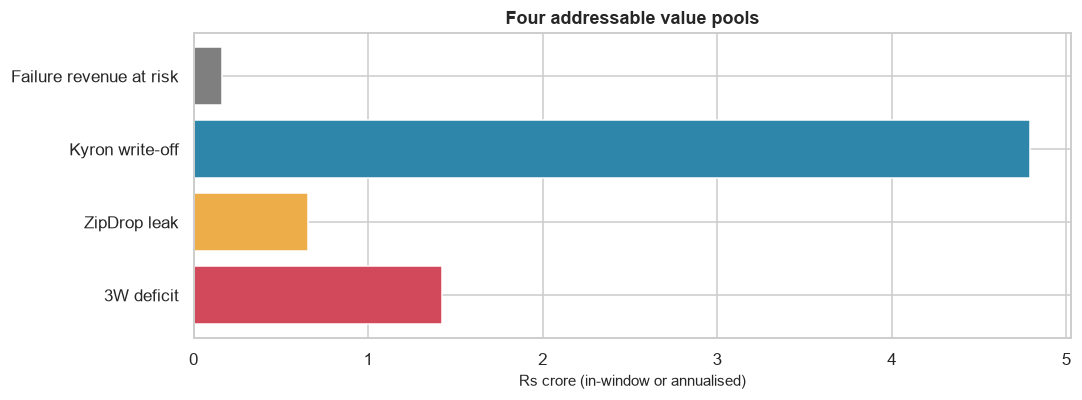

In [34]:
g1 = swaps[swaps.charger_generation == 'Gen1']
g23 = swaps[swaps.charger_generation.isin(['Gen2','Gen3'])]
gen1_excess = len(g1)*(g1.is_failed.mean()-g23.is_failed.mean())
top30 = st.nlargest(30, 'fail')
fail_avoidable = (top30.fail - swaps.is_failed.mean()).clip(lower=0).mul(top30.attempts).sum()
avg_price = completed.amount_charged_inr.mean()
threew = completed[completed.vehicle_class == '3W']
zd_post = c[(c.partner=='ZipDrop') & c.post_amend].shape[0]
zd_leak = 12.99 * zd_post / 8 * 12

print('QUANTIFIED DRIVERS')
print('-'*76)
print('1. Recoverable failures, worst 30 stations : %10s attempts (~Rs %.2f cr revenue)' % (f'{fail_avoidable:,.0f}', fail_avoidable*avg_price/1e7))
print('2. Gen-1 excess failure vs Gen-2/3        : %10s attempts (~Rs %.2f cr revenue)' % (f'{gen1_excess:,.0f}', gen1_excess*avg_price/1e7))
print('3. Kyron retirement write-off              : Rs %.2f cr (one-off)' % (b[b.retired].purchase_cost_inr.sum()/1e7))
print('4. 3W contribution deficit                : Rs %.2f cr in-window' % (-threew.cm.sum()/1e7))
print('5. ZipDrop discount give-up               : Rs %.2f cr annualised' % (zd_leak/1e7))
print('6. All failed attempts (foregone revenue)  : Rs %.2f cr in-window' % (swaps.is_failed.sum()*avg_price/1e7))
print('-'*76)
print('Network contribution margin, in-window     : Rs %.2f cr' % (tot['cm']/1e7))

fig, ax = plt.subplots(figsize=(10, 3.8))
items = {'3W deficit': -threew.cm.sum()/1e7, 'ZipDrop leak': zd_leak/1e7,
         'Kyron write-off': b[b.retired].purchase_cost_inr.sum()/1e7,
         'Failure revenue at risk': fail_avoidable*avg_price/1e7}
ax.barh(list(items), list(items.values()), color=['#d1495b','#edae49','#2e86ab','#7f7f7f'])
ax.set_xlabel('Rs crore (in-window or annualised)')
ax.set_title('Four addressable value pools')
save(fig, 'f19_value_pools.png')
plt.show()